# Trabajo Práctico Especial - Fundamentos de la Ciencia de Datos (2026)
## Análisis del conjunto de datos: Stack Overflow Developer Survey 2025

---

# 1. Análisis exploratorio inicial de la base

### 1.1. Origen de los datos y descarga de archivos
El conjunto de datos corresponde a la encuesta anual **Stack Overflow Developer Survey 2025**, realizada de forma online por la plataforma Stack Overflow a desarrolladores y profesionales de tecnología de todo el mundo. Al tratarse de una encuesta voluntaria y autoadministrada vía web, es importante tener en cuenta que los datos reflejan las respuestas declaradas por los propios usuarios (lo que puede incluir preguntas sin responder o errores de carga manual en campos abiertos).

A continuación, descargamos de forma automatizada tanto el archivo de metadatos (`metadatos.csv`), que describe la estructura del cuestionario, como el conjunto de datos con los resultados (`dataset.csv`).

In [4]:
from wget import download
from os import path, listdir
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuramos Pandas para visualizar todas las columnas sin truncar la tabla
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

url_metadatos = "https://media.githubusercontent.com/media/StackExchange/Survey/refs/heads/main/packages/archive/2025/schema.csv"
url_dataset = "https://media.githubusercontent.com/media/StackExchange/Survey/6ae2209cd35a55e92739ba82f7887fb86807a069/packages/archive/2025/results.csv"

# Descargamos el archivo de metadatos si no existe localmente
if not path.exists("metadatos.csv"):
    download(url_metadatos, "metadatos.csv")
else:
    print("ya existe el archivo")

# Descargamos el archivo del dataset si no existe localmente
if not path.exists("dataset.csv"):
    download(url_dataset, "dataset.csv")
else:
    print("ya existe el archivo")

# Chequeamos que los archivos estén en el directorio actual
lista_archivos = listdir("./")
print(f"El contenido de la carpeta es: {lista_archivos}")

ya existe el archivo
ya existe el archivo
El contenido de la carpeta es: ['.git', '.gitignore', 'dataset.csv', 'dataset_limpio.pkl', 'ejercicios.ipynb', 'metadatos.csv', 'tp_especial.ipynb', 'venv']


### 1.2. Lectura de los archivos CSV y exploración de Metadatos
Utilizamos la función `read_csv()` de Pandas para levantar ambos archivos en objetos de tipo `DataFrame`. Primero inspeccionamos el tamaño de ambas tablas con `shape` y visualizamos el archivo `metadatos.csv` para comprender cómo se documentan las preguntas de la encuesta.

In [5]:
# Abrimos ambos archivos CSV usando Pandas
metadatos = pd.read_csv("metadatos.csv")
raw_dataset = pd.read_csv("dataset.csv", low_memory=False)

print(f"Dimensiones de metadatos (filas, columnas): {metadatos.shape}")
print(f"Dimensiones de raw_dataset (filas, columnas): {raw_dataset.shape}")

# Visualizamos las primeras filas de la tabla de metadatos para entender la estructura de los datos
metadatos.head(50)

Dimensiones de metadatos (filas, columnas): (139, 6)
Dimensiones de raw_dataset (filas, columnas): (49191, 172)


,qid,qname,question,type,sub,sq_id
0,QID18,TechEndorse_1,What attracts you to a technology or causes yo...,RO,AI integration or AI Agent capabilities,1.0
1,QID18,TechEndorse_2,What attracts you to a technology or causes yo...,RO,Easy-to-use API,2.0
2,QID18,TechEndorse_3,What attracts you to a technology or causes yo...,RO,Robust and complete API,3.0
3,QID18,TechEndorse_4,What attracts you to a technology or causes yo...,RO,Customizable and manageable codebase,4.0
4,QID18,TechEndorse_5,What attracts you to a technology or causes yo...,RO,Reputation for quality,5.0
5,QID18,TechEndorse_6,What attracts you to a technology or causes yo...,RO,Connected to an open-source project,6.0
6,QID18,TechEndorse_7,What attracts you to a technology or causes yo...,RO,Good brand and public image,7.0
7,QID18,TechEndorse_8,What attracts you to a technology or causes yo...,RO,Reliability and low latency,8.0
8,QID18,TechEndorse_9,What attracts you to a technology or causes yo...,RO,Costs are manageable,9.0
9,QID18,TechEndorse_13,What attracts you to a technology or causes yo...,RO,Other (please specify):,10.0


Al observar las dimensiones, notamos que `metadatos` tiene **139 filas** (cada una representa una pregunta o sub-pregunta del cuestionario), mientras que `raw_dataset` cuenta con **49.191 registros** (encuestados) y **172 columnas**.

Analizamos la columna `type` dentro de `metadatos` para entender qué tipos de preguntas componen la encuesta y por qué existen más columnas en el dataset que filas en los metadatos:
* **`RO` (Rank Order):** Preguntas donde el encuestado ordena opciones por prioridad (utilizan las columnas `sub` y `sq_id` para detallar cada ítem).
* **`MC` (Multiple Choice):** Preguntas de opción múltiple (de selección única o de selección múltiple).
* **`TE` (Text Entry):** Preguntas de entrada por teclado (números escritos manualmente o texto libre).
* **`Matrix`:** Preguntas en formato de tabla o matriz (por ejemplo, lenguajes o bases de datos trabajados este año vs. deseados para el próximo año), donde una única fila de `metadatos` se desglosa en varias columnas dentro de `raw_dataset`.

In [6]:
# Contamos cuántas preguntas hay de cada tipo según los metadatos
conteo_tipos_meta = metadatos["type"].value_counts()
print("Cantidad de preguntas por tipo en metadatos:")
print(conteo_tipos_meta)

# Verificamos qué preguntas de metadatos se desglosan en múltiples columnas en el dataset
preguntas_matrix = metadatos[metadatos["type"] == "Matrix"][["qid", "qname", "type"]]
print("\nPreguntas de tipo Matrix en metadatos:")
print(preguntas_matrix)

Cantidad de preguntas por tipo en metadatos:
type
RO        49
MC        48
TE        29
Matrix    13
Name: count, dtype: int64

Preguntas de tipo Matrix en metadatos:
       qid              qname    type
76   QID34           Language  Matrix
80   QID35           Database  Matrix
84   QID36           Platform  Matrix
88   QID37           Webframe  Matrix
92   QID38            DevEnvs  Matrix
95   QID39             SOTags  Matrix
98   QID40              OpSys  Matrix
99   QID41   OfficeStackAsync  Matrix
102  QID42       CommPlatform  Matrix
106  QID43           AIModels  Matrix
120  QID82             AITool  Matrix
127  QID87      AIAgentImpact  Matrix
128  QID88  AIAgentChallenges  Matrix


### 1.3. Primera exploración del conjunto de datos (`raw_dataset`)
Inspeccionamos los primeros 5 registros del conjunto de datos utilizando el método `head()`, y luego ejecutamos `info()` para conocer el listado de columnas, la cantidad de valores no nulos y el tipo de dato (`dtype`) asignado por Pandas a cada atributo.

In [7]:
# Mostramos los primeros 5 registros del dataset
raw_dataset.head()

,ResponseId,MainBranch,Age,EdLevel,Employment,EmploymentAddl,WorkExp,LearnCodeChoose,LearnCode,LearnCodeAI,AILearnHow,YearsCode,DevType,OrgSize,ICorPM,RemoteWork,PurchaseInfluence,TechEndorseIntro,TechEndorse_1,TechEndorse_2,TechEndorse_3,TechEndorse_4,TechEndorse_5,TechEndorse_6,TechEndorse_7,TechEndorse_8,TechEndorse_9,TechEndorse_13,TechEndorse_13_TEXT,TechOppose_1,TechOppose_2,TechOppose_3,TechOppose_5,TechOppose_7,TechOppose_9,TechOppose_11,TechOppose_13,TechOppose_16,TechOppose_15,TechOppose_15_TEXT,Industry,JobSatPoints_1,JobSatPoints_2,JobSatPoints_3,JobSatPoints_4,JobSatPoints_5,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,JobSatPoints_13,JobSatPoints_14,JobSatPoints_15,JobSatPoints_16,JobSatPoints_15_TEXT,AIThreat,NewRole,ToolCountWork,ToolCountPersonal,Country,Currency,CompTotal,LanguageChoice,LanguageHaveWorkedWith,LanguageWantToWorkWith,LanguageAdmired,LanguagesHaveEntry,LanguagesWantEntry,DatabaseChoice,DatabaseHaveWorkedWith,DatabaseWantToWorkWith,DatabaseAdmired,DatabaseHaveEntry,DatabaseWantEntry,PlatformChoice,PlatformHaveWorkedWith,PlatformWantToWorkWith,PlatformAdmired,PlatformHaveEntry,PlatformWantEntry,WebframeChoice,WebframeHaveWorkedWith,WebframeWantToWorkWith,WebframeAdmired,WebframeHaveEntry,WebframeWantEntry,DevEnvsChoice,DevEnvsHaveWorkedWith,DevEnvsWantToWorkWith,DevEnvsAdmired,DevEnvHaveEntry,DevEnvWantEntry,SOTagsHaveWorkedWith,SOTagsWantToWorkWith,SOTagsAdmired,SOTagsHaveEntry,SOTagsWant Entry,OpSysPersonal use,OpSysProfessional use,OfficeStackAsyncHaveWorkedWith,OfficeStackAsyncWantToWorkWith,OfficeStackAsyncAdmired,OfficeStackHaveEntry,OfficeStackWantEntry,CommPlatformHaveWorkedWith,CommPlatformWantToWorkWith,CommPlatformAdmired,CommPlatformHaveEntr,CommPlatformWantEntr,AIModelsChoice,AIModelsHaveWorkedWith,AIModelsWantToWorkWith,AIModelsAdmired,AIModelsHaveEntry,AIModelsWantEntry,SOAccount,SOVisitFreq,SODuration,SOPartFreq,SO_Dev_Content,SO_Actions_1,SO_Actions_16,SO_Actions_3,SO_Actions_4,SO_Actions_5,SO_Actions_6,SO_Actions_9,SO_Actions_7,SO_Actions_10,SO_Actions_15,SO_Actions_15_TEXT,SOComm,SOFriction,AISelect,AISent,AIAcc,AIComplex,AIToolCurrently partially AI,AIToolDon't plan to use AI for this task,AIToolPlan to partially use AI,AIToolPlan to mostly use AI,AIToolCurrently mostly AI,AIFrustration,AIExplain,AIAgents,AIAgentChange,AIAgent_Uses,AgentUsesGeneral,AIAgentImpactSomewhat agree,AIAgentImpactNeutral,AIAgentImpactSomewhat disagree,AIAgentImpactStrongly agree,AIAgentImpactStrongly disagree,AIAgentChallengesNeutral,AIAgentChallengesSomewhat disagree,AIAgentChallengesStrongly agree,AIAgentChallengesSomewhat agree,AIAgentChallengesStrongly disagree,AIAgentKnowledge,AIAgentKnowWrite,AIAgentOrchestration,AIAgentOrchWrite,AIAgentObserveSecure,AIAgentObsWrite,AIAgentExternal,AIAgentExtWrite,AIHuman,AIOpen,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,25-34 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Employed,"Caring for dependents (children, elderly, etc.)",8.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",AI CodeGen tools or AI-enabled apps,14.0,"Developer, mobile",20 to 99 employees,People manager,Remote,"Yes, I influenced the purchase of a substantia...",Work,10.0,7.0,9.0,6.0,3.0,11.0,12.0,1.0,8.0,14.0,NaN,15.0,7.0,8.0,12.0,11.0,1.0,6.0,13.0,3.0,16.0,NaN,Fintech,3.0,1.0,4.0,9.0,5.0,10.0,12.0,11.0,2.0,6.0,7.0,13.0,14.0,15.0,8.0,NaN,I'm not sure,I have neither consider or transitioned into a...,7.0,3.0,Ukraine,EUR European Euro,52800.0,Yes,Bash/Shell (all shells);Dart;SQL,Dart,Dart,NaN,NaN,Yes,Cloud Firestore;PostgreSQL,NaN,NaN,NaN,NaN,Yes,Amazon Web Services (AWS);Cloudflare;Firebase;...,NaN,NaN,NaN,NaN,No,NaN,NaN,NaN,NaN,NaN,Yes,Android Studio;Notepad++;Visual Studio;Visual ...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Windows;MacOS;Android,Windows;MacOS;Android;iOS;iPadOS,Confluence;GitHub;GitLab;Jira;Markdo

In [8]:
# Revisamos el resumen de tipos de datos y el detalle de columnas con info()
print("Resumen de tipos de datos en las 172 columnas:")
print(raw_dataset.dtypes.value_counts())
print("\nInformación detallada del DataFrame:")
raw_dataset.info(verbose=True, show_counts=True)

Resumen de tipos de datos en las 172 columnas:
str        119
float64     52
int64        1
Name: count, dtype: int64

Información detallada del DataFrame:
<class 'pandas.DataFrame'>
RangeIndex: 49191 entries, 0 to 49190
Data columns (total 172 columns):
 #    Column                                    Non-Null Count  Dtype  
---   ------                                    --------------  -----  
 0    ResponseId                                49191 non-null  int64  
 1    MainBranch                                49191 non-null  str    
 2    Age                                       49191 non-null  str    
 3    EdLevel                                   48149 non-null  str    
 4    Employment                                48339 non-null  str    
 5    EmploymentAddl                            44875 non-null  str    
 6    WorkExp                                   42893 non-null  float64
 7    LearnCodeChoose                           46858 non-null  str    
 8    LearnCode          

### 1.4. Estadísticas descriptivas básicas de las variables numéricas
Utilizamos el método `describe()` para obtener las estadísticas descriptivas principales (cantidad de registros no nulos `count`, media `mean`, desvío estándar `std`, valor mínimo `min`, cuartiles `25%`, `50%` o mediana, `75%`, y valor máximo `max`) de las variables que Pandas interpretó como numéricas.

In [9]:
# Calculamos las estadísticas descriptivas de las columnas numéricas
raw_dataset.describe()

,ResponseId,WorkExp,YearsCode,TechEndorse_1,TechEndorse_2,TechEndorse_3,TechEndorse_4,TechEndorse_5,TechEndorse_6,TechEndorse_7,TechEndorse_8,TechEndorse_9,TechEndorse_13,TechOppose_1,TechOppose_2,TechOppose_3,TechOppose_5,TechOppose_7,TechOppose_9,TechOppose_11,TechOppose_13,TechOppose_16,TechOppose_15,JobSatPoints_1,JobSatPoints_2,JobSatPoints_3,JobSatPoints_4,JobSatPoints_5,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,JobSatPoints_13,JobSatPoints_14,JobSatPoints_15,JobSatPoints_16,ToolCountWork,ToolCountPersonal,CompTotal,SO_Actions_1,SO_Actions_16,SO_Actions_3,SO_Actions_4,SO_Actions_5,SO_Actions_6,SO_Actions_9,SO_Actions_7,SO_Actions_10,SO_Actions_15,ConvertedCompYearly,JobSat
count,49191.000000,42893.000000,43042.000000,35975.000000,35975.000000,35975.000000,35975.000000,35975.000000,35975.000000,35975.000000,35975.000000,35975.000000,35975.000000,34259.000000,34259.000000,34259.000000,34259.000000,34259.000000,34259.000000,34259.000000,34259.000000,34259.000000,34259.000000,24943.000000,24943.000000,24943.000000,24943.000000,24943.000000,24943.000000,24943.000000,24943.000000,24943.000000,24943.000000,24943.000000,24943.000000,24943.000000,24943.000000,24943.000000,27611.000000,25582.000000,2.486600e+04,26260.000000,24340.000000,26260.000000,26260.000000,26260.000000,26260.000000,26260.000000,26260.000000,26260.000000,26260.000000,2.394700e+04,26670.000000
mean,24596.000000,13.367403,16.570861,7.867352,4.104211,4.110271,5.678193,4.119388,5.225990,6.477387,4.370841,4.431661,9.854315,8.307948,4.524067,5.925567,4.991710,4.048980,3.799323,4.365831,5.059867,5.508538,9.945766,6.867738,5.216173,7.455719,9.537947,9.758209,8.194965,5.884096,7.367799,6.744658,7.512569,5.703283,8.563324,8.679349,14.687487,7.826685,17.734852,8.545579,2.234198e+70,4.907845,3.339770,5.718355,4.561767,4.790861,5.199657,5.676314,4.984653,7.099505,10.079284,1.017615e+05,7.201950
std,14200.362883,10.800117,11.787610,2.397432,2.275821,2.329536,2.398084,2.437945,2.801045,2.331468,2.357058,2.620901,1.975692,2.202164,2.282867,2.301937,2.294707,2.607443,2.499468,2.557152,2.533541,2.906146,2.087463,3.741490,3.660632,3.726759,3.781286,3.557588,3.801257,3.900813,4.118532,3.888845,3.847265,4.110528,3.545288,3.633175,1.898188,4.077460,269.810134,44.664738,3.523096e+72,2.682204,2.411404,2.628016,3.070548,2.643177,2.563562,2.310659,2.490095,2.469394,1.940928,4.617569e+05,1.997245
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000e+00,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000e+00,0.000000
25%,12298.500000,5.000000,8.000000,7.000000,2.000000,2.000000,4.000000,2.000000,3.000000,5.000000,2.000000,2.000000,10.000000,8.000000,3.000000,4.000000,3.000000,2.000000,2.000000,2.000000,3.000000,3.000000,10.000000,4.000000,2.000000,4.000000,7.000000,7.000000,5.000000,2.000000,4.000000,3.000000,4.000000,2.000000,6.000000,6.000000,15.000000,4.000000,4.000000,3.000000,5.500000e+04,3.000000,1.000000,3.000000,1.000000,3.000000,3.000000,4.000000,3.000000,6.000000,10.000000,3.817100e+04,6.000000
50%,24596.000000,10.000000,14.000000,9.000000,4.000000,4.000000,6.000000,4.000000,5.000000,7.000000,4.000000,4.000000,10.000000,9.000000,4.000000,6.000000,5.000000,4.000000,3.000000,4.000000,5.000000,6.000000,10.000000,6.000000,4.000000,7.000000,10.000000,10.000000,8.000000,5.000000,7.000000,6.000000,7.000000,5.000000,9.000000,9.000000,15.000000,8.000000,6.000000,5.000000,1.050000e+05,5.000000,2.000000,6.000000,4.000000,5.000000,5.000000,6.000000,5.000000,8.000000,10.000000,7.532000e+04,8.000000
75%,36893.500000,20.000000,24.000000,9.000000,6.000000,6.000000,8.000000,6.000000,8

Al analizar la tabla generada por `describe()`, identificamos comportamientos y anomalías claras en los atributos numéricos que deberán ser tenidos en cuenta durante la etapa de limpieza:

* **`WorkExp` y `YearsCode`:** Representan los años de experiencia profesional y los años totales programando. La mediana (`50%`) es de **10 años** para `WorkExp` y de **14 años** para `YearsCode`. Sin embargo, ambas presentan un valor mínimo de `1.0` (la instrucción de dejar vacío cuando la respuesta es 0 corresponde únicamente a `WorkExp`; no implica que todos sus faltantes representen cero) y un valor máximo irreal de **100 años**, lo que requiere inspeccionar estos valores y su relación con la edad antes de decidir si son errores.
* **`ToolCountWork` y `ToolCountPersonal`:** Miden la cantidad de herramientas de software utilizadas en el trabajo y en proyectos personales. Aunque el 75% de los encuestados utiliza hasta 10 herramientas en el trabajo (mediana de 6) y hasta 7 en uso personal (mediana de 5), aparecen máximos extremos de **10.000** y **1.000** respectivamente, distorsionando la media y el desvío estándar.
* **`CompTotal` y `ConvertedCompYearly`:** `CompTotal` expresa el salario anual en la moneda local de cada encuestado (mezclando distintas divisas) y presenta un máximo absurdo de $5.55 \times 10^{74}$ que debe revisarse. Además, mezclar monedas locales impide interpretar su media global como una remuneración comparable. Por su parte, `ConvertedCompYearly` (salario anual estandarizado en dólares estadounidenses) muestra una mediana razonable de **75.320 USD**, pero presenta valores atípicos extremos tanto en su mínimo (**1 USD anual**) como en su máximo (**50.000.000 USD anuales**).
* **`JobSat`:** Mide la satisfacción laboral general en una escala de **0 a 10**. Se comporta dentro del rango teórico esperado, con una media de **7,20** y una mediana de **8,0**.
* **Variables de ordenamiento (`TechEndorse_*`, `TechOppose_*`, `JobSatPoints_*`, `SO_Actions_*`):** Corresponden a preguntas de tipo *Rank Order* (`RO`), donde los valores numéricos (entre 1 y 15) indican la posición o prioridad asignada por el usuario a cada opción.

### 1.5. Distribución de las variables cuantitativas principales (Histogramas)
Siguiendo lo visto en la práctica de visualización, construimos los histogramas de las variables cuantitativas principales (`WorkExp`, `YearsCode`, `JobSat`, `ToolCountWork`, `ToolCountPersonal` y `ConvertedCompYearly`) para observar la forma de sus distribuciones, su asimetría y el efecto visual de los valores atípicos detectados.

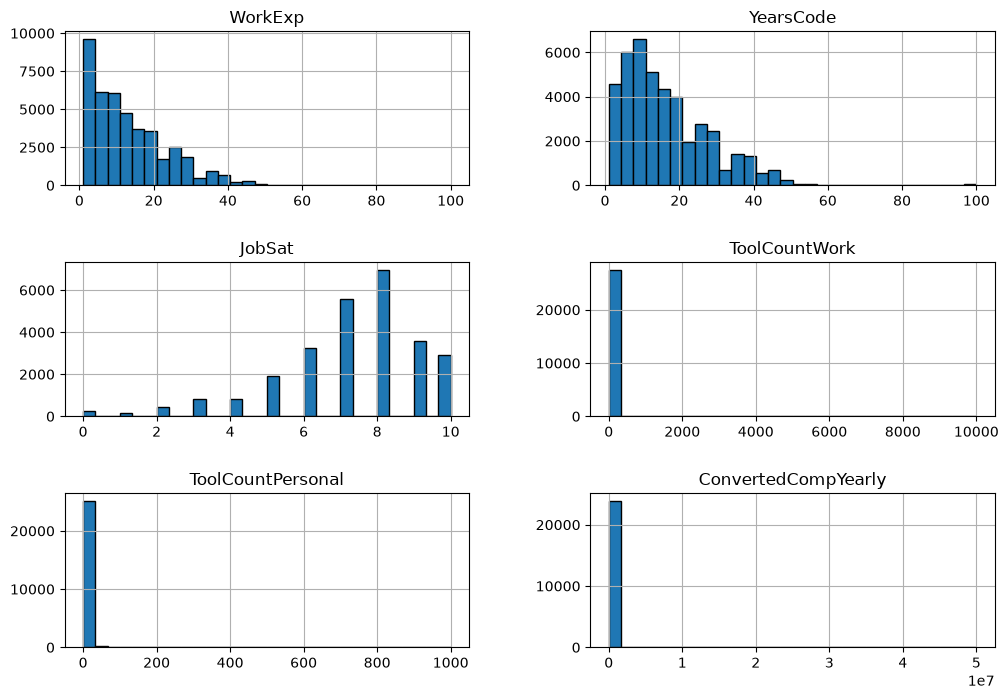

In [10]:
# Seleccionamos las variables cuantitativas principales (excluyendo el ID y las de ranking)
columnas_cuantitativas = [
    "WorkExp", "YearsCode", "JobSat", 
    "ToolCountWork", "ToolCountPersonal", "ConvertedCompYearly"
]

# Construimos los histogramas mostrando la distribución de las features
raw_dataset[columnas_cuantitativas].hist(figsize=(12, 8), bins=30, edgecolor="black")
plt.subplots_adjust(hspace=0.5, wspace=0.3)
plt.show()

En los histogramas obtenidos se observa claramente el efecto de los valores extremos:
* **`WorkExp` y `YearsCode`:** Presentan distribuciones con asimetría positiva (concentradas entre 1 y aproximadamente 25/30 años), pero el eje horizontal se extiende hasta 100 debido a casos aislados con valores no representativos.
* **`JobSat`:** Al ser una escala entera de 0 a 10, las barras quedan separadas en cada valor discreto, mostrando una clara acumulación entre los niveles 7 y 8.
* **`ToolCountWork`, `ToolCountPersonal` y `ConvertedCompYearly`:** Casi la totalidad de las muestras queda concentrada en la primera barra a la izquierda. Esto ocurre porque unos pocos valores atípicos extremos (como 10.000 herramientas o 50 millones de dólares) estiran la escala del eje X, impidiendo visualizar la distribución real del resto de los datos sin antes aplicar una limpieza de outliers.

---

### 1.6. Análisis de valores nulos y completitud de registros
Siguiendo la metodología de la práctica, utilizamos `isna().sum()` para contabilizar la cantidad de valores faltantes (`NaN`) por columna. Además, dado que se trata de una encuesta online donde los usuarios pueden abandonar el cuestionario sin finalizarlo o saltear secciones, contamos los campos completos por encuestado. No equivale al número de preguntas respondidas: las matrices y los rankings ocupan varias columnas y algunas preguntas no aplican a todos los perfiles.

In [11]:
# Calculamos la cantidad y el porcentaje de valores nulos por columna
nulos_por_columna = raw_dataset.isna().sum()
porcentaje_nulos = (raw_dataset.isna().sum() / raw_dataset.shape[0]) * 100

# Armamos una tabla resumen ordenada de menor a mayor cantidad de nulos
resumen_nulos = pd.DataFrame({
    "Cantidad_Nulos": nulos_por_columna,
    "Porcentaje_Nulos": porcentaje_nulos
}).sort_values(by="Cantidad_Nulos")

print("Primeras 15 columnas con MENOS valores nulos:")
print(resumen_nulos.head(15))

print("\nÚltimas 15 columnas con MÁS valores nulos:")
print(resumen_nulos.tail(30))

Primeras 15 columnas con MENOS valores nulos:
                   Cantidad_Nulos  Porcentaje_Nulos
ResponseId                      0          0.000000
MainBranch                      0          0.000000
Age                             0          0.000000
Employment                    852          1.732024
EdLevel                      1042          2.118274
LearnCodeChoose              2333          4.742737
LearnCodeAI                  3990          8.111240
EmploymentAddl               4316          8.773963
DevType                      5511         11.203269
YearsCode                    6149         12.500254
WorkExp                      6298         12.803155
TechEndorseIntro            11635         23.652701
PurchaseInfluence           11754         23.894615
AIThreat                    13113         26.657315
TechEndorse_2               13216         26.866703

Últimas 15 columnas con MÁS valores nulos:
                                Cantidad_Nulos  Porcentaje_Nulos
LanguagesHave

Estadísticas de cantidad de campos completos por encuestado:
count    49191.000000
mean        80.789413
std         45.961061
min          2.000000
25%         36.000000
50%         99.000000
75%        120.000000
max        155.000000
dtype: float64


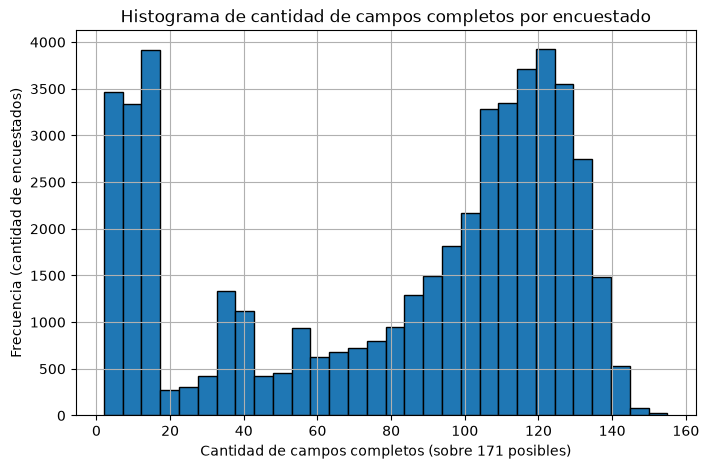

In [12]:
# Contamos cuántas campos no nulos respondió cada persona (sin contar ResponseId)
respuestas_por_encuestado = raw_dataset.drop("ResponseId", axis=1).notna().sum(axis=1)

print("Estadísticas de cantidad de campos completos por encuestado:")
print(respuestas_por_encuestado.describe())

# Graficamos el histograma de campos completos por fila
plt.figure(figsize=(8, 5))
plt.hist(respuestas_por_encuestado, bins=30, edgecolor="black")
plt.xlabel("Cantidad de campos completos (sobre 171 posibles)")
plt.ylabel("Frecuencia (cantidad de encuestados)")
plt.title("Histograma de cantidad de campos completos por encuestado")
plt.grid(True)
plt.show()

### 1.7. Exploración de variables categóricas relevantes (`value_counts`)
Utilizamos el método `value_counts()` para inspeccionar las frecuencias absolutas de las principales variables cualitativas del conjunto, verificando además si existen valores que representen datos faltantes o respuestas evasivas (como `"Prefer not to say"`).

In [13]:
# Exploramos las variables demográficas y laborales principales
columnas_categoricas = [
    "MainBranch", "Age", "EdLevel", "Employment", 
    "RemoteWork", "ICorPM", "AISelect", "AIAcc", "NewRole"
]

for col in columnas_categoricas:
    print(f"=== Frecuencias de {col} ===")
    print(raw_dataset[col].value_counts(dropna=False))
    print("-" * 50)

=== Frecuencias de MainBranch ===
MainBranch
I am a developer by profession                                                                37467
I am not primarily a developer, but I write code sometimes as part of my work/studies          4894
I am learning to code                                                                          2585
I code primarily as a hobby                                                                    1924
I used to be a developer by profession, but no longer am                                       1325
I work with developers or my work supports developers but am not a developer by profession      996
Name: count, dtype: int64
--------------------------------------------------
=== Frecuencias de Age ===
Age
25-34 years old      16519
35-44 years old      13241
18-24 years old       9210
45-54 years old       6275
55-64 years old       2626
65 years or older      942
Prefer not to say      378
Name: count, dtype: int64
--------------------------------

In [14]:
# Exploramos los 15 países con mayor cantidad de respuestas y verificamos la posición de Argentina
print("=== Top 15 Países con más respuestas ===")
print(raw_dataset["Country"].value_counts().head(15))

# Contamos cuántos registros corresponden específicamente a Argentina
num_argentina = raw_dataset[raw_dataset["Country"] == "Argentina"].shape[0]
print(f"\nCantidad de encuestados de Argentina: {num_argentina}")

=== Top 15 Países con más respuestas ===
Country
United States of America                                7233
Germany                                                 3025
India                                                   2547
United Kingdom of Great Britain and Northern Ireland    2042
France                                                  1409
Canada                                                  1305
Ukraine                                                  964
Poland                                                   888
Netherlands                                              867
Italy                                                    835
Brazil                                                   825
Australia                                                804
Spain                                                    717
Sweden                                                   616
Switzerland                                              546
Name: count, dtype: int64

Cantidad 

De la exploración de valores nulos y frecuencias categóricas se desprenden tres observaciones fundamentales para la posterior limpieza:
1. **Columnas con más del 95% de nulos:** Las columnas con mayor cantidad de faltantes (entre 96% y 99,5% de `NaN`) corresponden a campos opcionales de texto libre (`*_TEXT`, `*HaveEntry`, `*WantEntry`, `*Write`) que solo se completaban si la opción buscada por el usuario no figuraba en las listas predefinidas.
2. **Composición de la muestra (`MainBranch`) y nulos estructurales:** Si bien el 76,2% de los encuestados son desarrolladores profesionales (37.467 casos), el conjunto incluye estudiantes, programadores por hobby y ex-desarrolladores. Esto explica que atributos exclusivamente laborales (como `RemoteWork`, `JobSat` o `ConvertedCompYearly`) presenten entre un 30% y un 50% de valores nulos.
3. **Valores faltantes codificados como texto:** En variables como `Age` aparece la categoría `"Prefer not to say"` (378 registros), la cual funciona en la práctica como un valor nulo.

---

### 1.8. Detección de valores atípicos (outliers) e inconsistencias en los datos
Para evidenciar gráficamente los valores atípicos detectados previamente en `describe()`, utilizamos diagramas de caja (`boxplot`) sobre las variables numéricas principales. Además, verificamos en los datos crudos la existencia de inconsistencias lógicas entre variables (por ejemplo, años de experiencia que superan la edad máxima del intervalo declarado. La comparación WorkExp > YearsCode se inspecciona, pero no prueba una inconsistencia porque WorkExp mide experiencia profesional general).

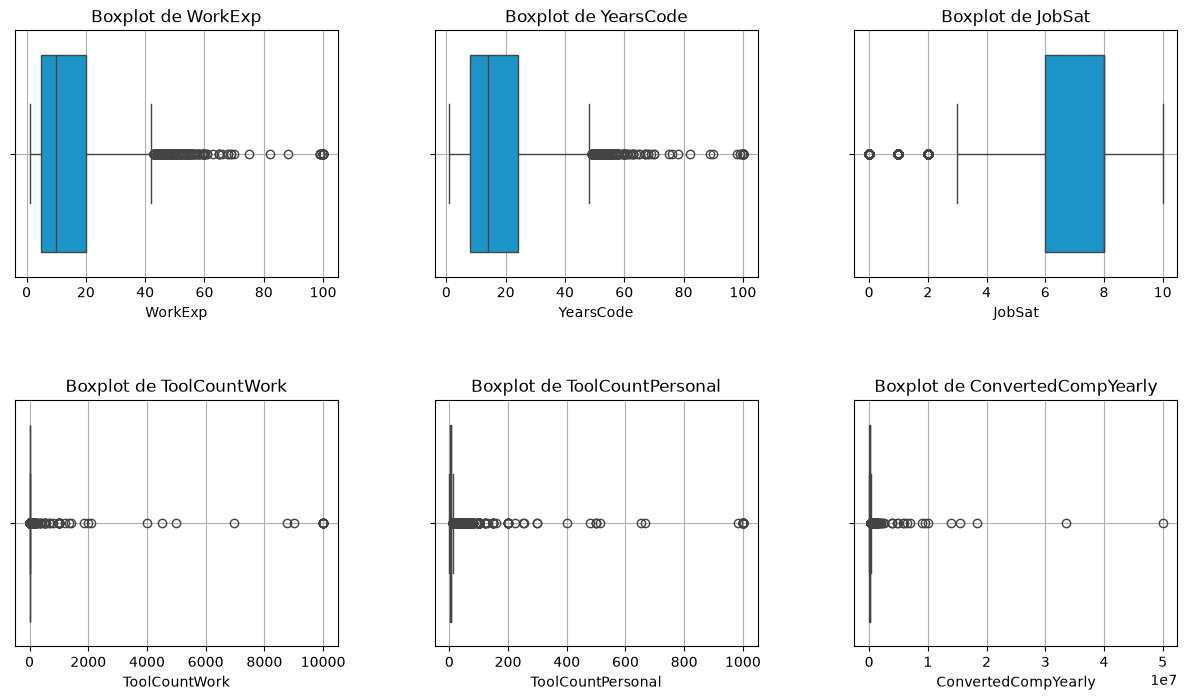

In [15]:
# Creamos diagramas de caja (boxplots) para visualizar los outliers en las variables cuantitativas
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(columnas_cuantitativas):
    sns.boxplot(x=raw_dataset[col], ax=axes[i], color="#009FE4")
    axes[i].set_title(f"Boxplot de {col}")
    axes[i].set_xlabel(col)
    axes[i].grid(True)

plt.subplots_adjust(hspace=0.5, wspace=0.3)
plt.show()

In [16]:
# Verificamos cuántos registros presentan valores extremos o inconsistencias lógicas en raw_dataset
mas_de_50_exp = raw_dataset[raw_dataset["WorkExp"] > 50].shape[0]
mas_de_50_code = raw_dataset[raw_dataset["YearsCode"] > 50].shape[0]
exp_mayor_que_code = raw_dataset[raw_dataset["WorkExp"] > raw_dataset["YearsCode"]].shape[0]
herramientas_excesivas = raw_dataset[raw_dataset["ToolCountWork"] > 100].shape[0]
sueldos_extremos = raw_dataset[raw_dataset["ConvertedCompYearly"] > 1000000].shape[0]
sueldos_irrisorios = raw_dataset[raw_dataset["ConvertedCompYearly"] < 100].shape[0]

print(f"Registros con WorkExp > 50 años: {mas_de_50_exp}")
print(f"Registros con YearsCode > 50 años: {mas_de_50_code}")
print(f"Casos con WorkExp > YearsCode (no necesariamente errores): {exp_mayor_que_code}")
print(f"Registros con ToolCountWork > 100 herramientas: {herramientas_excesivas}")
print(f"Registros con sueldo anual > 1.000.000 USD: {sueldos_extremos}")
print(f"Registros con sueldo anual < 100 USD: {sueldos_irrisorios}")

# Mostramos algunos ejemplos concretos de estos registros atípicos
raw_dataset[raw_dataset["WorkExp"] > 60][["ResponseId", "Age", "WorkExp", "YearsCode", "ConvertedCompYearly"]].head(10)

Registros con WorkExp > 50 años: 147
Registros con YearsCode > 50 años: 248
Casos con WorkExp > YearsCode (no necesariamente errores): 3564
Registros con ToolCountWork > 100 herramientas: 95
Registros con sueldo anual > 1.000.000 USD: 46
Registros con sueldo anual < 100 USD: 304


,ResponseId,Age,WorkExp,YearsCode,ConvertedCompYearly
2520,2521,65 years or older,65.0,65.0,NaN
3285,3286,65 years or older,100.0,49.0,NaN
4933,4934,45-54 years old,100.0,100.0,NaN
5430,5431,65 years or older,68.0,55.0,NaN
6064,6065,Prefer not to say,99.0,99.0,NaN
7881,7882,25-34 years old,100.0,100.0,NaN
7940,7941,25-34 years old,69.0,69.0,NaN
10238,10239,65 years or older,61.0,4.0,NaN
11064,11065,25-34 years old,100.0,100.0,100.0
12140,12141,35-44 years old,100.0,100.0,100.0


Los resultados obtenidos confirman la presencia de anomalías que debemos abordar en la etapa de limpieza:
* Existen registros donde el usuario completó sistemáticamente el número `100` en todos los campos numéricos (por ejemplo, los registros con `ResponseId` 11065 y 12141 tienen entre 25 y 44 años y declaran 100 años de experiencia, 100 años programando y 100 USD de salario anual).
* Se observan casos biológicamente imposibles donde los años de experiencia laboral (`WorkExp`) o programando (`YearsCode`) superan la edad misma del encuestado (por ejemplo, personas de 25 a 34 años con 69 o 100 años de experiencia).
* Respecto a los 3.564 casos donde `WorkExp > YearsCode`, esto se explica por la redacción de la pregunta en la encuesta (*"How many years of professional work experience do you have?"*), ya que profesionales que trabajaron previamente en otra industria antes de aprender a programar declaran su antigüedad laboral total en `WorkExp`. Por lo tanto, no corresponde eliminarlos automáticamente salvo que contradigan la edad de la persona.(Es una variable que hay que tener cuidado al tenerla en cuenta para alguna hipotesis debido a su ambiguedad)

---

# 2. Operaciones de limpieza de la base

Para preservar intacto el conjunto de datos original (`raw_dataset`), comenzamos generando una copia de trabajo llamada `preprocessed_dataset` utilizando el método `copy()`, sobre la cual aplicaremos todas las acciones correctivas justificadas.

### 2.1. Eliminación de columnas fuera del alcance del análisis
Siguiendo la sección 1 de la Práctica 4, utilizamos `drop()` para excluir 28 campos abiertos que no utilizaremos en este trabajo. Es una selección de atributos, no una corrección de valores inválidos. No todos estos campos superan el 95% de faltantes: antes de eliminarlos mostramos su completitud real con `isna().sum()`. `raw_dataset` conserva los datos originales.

Referencia: Práctica 4, páginas 2–4; Clase 2, página 20. La elección concreta de estos 28 campos corresponde al alcance de nuestro estudio.

In [17]:
# Copiamos el conjunto original para preservarlo
preprocessed_dataset = raw_dataset.copy()

# Identificamos las 28 columnas de texto libre opcional (las terminadas en _TEXT, Entry, Entr, Write y abiertas)
columnas_texto_libre = [
    "TechEndorse_13_TEXT", "TechOppose_15_TEXT", "JobSatPoints_15_TEXT", "SO_Actions_15_TEXT",
    "LanguagesHaveEntry", "LanguagesWantEntry", "DatabaseHaveEntry", "DatabaseWantEntry",
    "PlatformHaveEntry", "PlatformWantEntry", "WebframeHaveEntry", "WebframeWantEntry",
    "DevEnvHaveEntry", "DevEnvWantEntry", "SOTagsHaveEntry", "SOTagsWant Entry",
    "OfficeStackHaveEntry", "OfficeStackWantEntry", "CommPlatformHaveEntr", "CommPlatformWantEntr",
    "AIModelsHaveEntry", "AIModelsWantEntry", "AIAgentKnowWrite", "AIAgentOrchWrite",
    "AIAgentObsWrite", "AIAgentExtWrite", "AIExplain", "AIOpen"
]

# Revisamos la cantidad y el porcentaje de nulos antes de excluir estos campos
print(preprocessed_dataset[columnas_texto_libre].isna().sum())
print((preprocessed_dataset[columnas_texto_libre].isna().sum() / len(preprocessed_dataset)) * 100)

# Eliminamos estas columnas del dataset preprocesado usando drop
preprocessed_dataset = preprocessed_dataset.drop(columnas_texto_libre, axis=1)

print(f"Columnas antes de drop: {raw_dataset.shape[1]}")
print(f"Columnas después de drop: {preprocessed_dataset.shape[1]}")

TechEndorse_13_TEXT     47182
TechOppose_15_TEXT      47544
JobSatPoints_15_TEXT    48527
SO_Actions_15_TEXT      48368
LanguagesHaveEntry      45209
LanguagesWantEntry      46041
DatabaseHaveEntry       47041
DatabaseWantEntry       47658
PlatformHaveEntry       45234
PlatformWantEntry       46091
WebframeHaveEntry       45897
WebframeWantEntry       46561
DevEnvHaveEntry         46429
DevEnvWantEntry         47079
SOTagsHaveEntry         48733
SOTagsWant Entry        48761
OfficeStackHaveEntry    46602
OfficeStackWantEntry    47574
CommPlatformHaveEntr    47715
CommPlatformWantEntr    48007
AIModelsHaveEntry       48415
AIModelsWantEntry       48716
AIAgentKnowWrite        48425
AIAgentOrchWrite        48713
AIAgentObsWrite         48927
AIAgentExtWrite         48332
AIExplain               22605
AIOpen                  26651
dtype: int64
TechEndorse_13_TEXT     95.915920
TechOppose_15_TEXT      96.651827
JobSatPoints_15_TEXT    98.650160
SO_Actions_15_TEXT      98.326930
LanguagesHa

### 2.2. Inspección de registros repetidos e información disponible
Siguiendo la sección 4 de la Práctica 4 (páginas 13–14), primero contamos los repetidos y mostramos las filas involucradas. En esta encuesta el identificador distingue las respuestas: personas diferentes pueden elegir las mismas categorías. Por eso, no aplicamos `drop_duplicates()` sobre las respuestas excluyendo el identificador.

In [18]:
# Contamos los identificadores repetidos
print("ResponseId repetidos:", raw_dataset["ResponseId"].duplicated().sum())

# Inspeccionamos respuestas coincidentes sin confundirlas con una misma persona
columnas_respuestas = raw_dataset.drop("ResponseId", axis=1).columns
cantidad_duplicados = raw_dataset.duplicated(subset=columnas_respuestas).sum()
print("Respuestas coincidentes sin considerar ResponseId:", cantidad_duplicados)
filas_duplicadas = raw_dataset[raw_dataset.duplicated(subset=columnas_respuestas, keep=False)]
filas_duplicadas.head(10)

ResponseId repetidos: 0
Respuestas coincidentes sin considerar ResponseId: 1547


,ResponseId,MainBranch,Age,EdLevel,Employment,EmploymentAddl,WorkExp,LearnCodeChoose,LearnCode,LearnCodeAI,AILearnHow,YearsCode,DevType,OrgSize,ICorPM,RemoteWork,PurchaseInfluence,TechEndorseIntro,TechEndorse_1,TechEndorse_2,TechEndorse_3,TechEndorse_4,TechEndorse_5,TechEndorse_6,TechEndorse_7,TechEndorse_8,TechEndorse_9,TechEndorse_13,TechEndorse_13_TEXT,TechOppose_1,TechOppose_2,TechOppose_3,TechOppose_5,TechOppose_7,TechOppose_9,TechOppose_11,TechOppose_13,TechOppose_16,TechOppose_15,TechOppose_15_TEXT,Industry,JobSatPoints_1,JobSatPoints_2,JobSatPoints_3,JobSatPoints_4,JobSatPoints_5,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,JobSatPoints_13,JobSatPoints_14,JobSatPoints_15,JobSatPoints_16,JobSatPoints_15_TEXT,AIThreat,NewRole,ToolCountWork,ToolCountPersonal,Country,Currency,CompTotal,LanguageChoice,LanguageHaveWorkedWith,LanguageWantToWorkWith,LanguageAdmired,LanguagesHaveEntry,LanguagesWantEntry,DatabaseChoice,DatabaseHaveWorkedWith,DatabaseWantToWorkWith,DatabaseAdmired,DatabaseHaveEntry,DatabaseWantEntry,PlatformChoice,PlatformHaveWorkedWith,PlatformWantToWorkWith,PlatformAdmired,PlatformHaveEntry,PlatformWantEntry,WebframeChoice,WebframeHaveWorkedWith,WebframeWantToWorkWith,WebframeAdmired,WebframeHaveEntry,WebframeWantEntry,DevEnvsChoice,DevEnvsHaveWorkedWith,DevEnvsWantToWorkWith,DevEnvsAdmired,DevEnvHaveEntry,DevEnvWantEntry,SOTagsHaveWorkedWith,SOTagsWantToWorkWith,SOTagsAdmired,SOTagsHaveEntry,SOTagsWant Entry,OpSysPersonal use,OpSysProfessional use,OfficeStackAsyncHaveWorkedWith,OfficeStackAsyncWantToWorkWith,OfficeStackAsyncAdmired,OfficeStackHaveEntry,OfficeStackWantEntry,CommPlatformHaveWorkedWith,CommPlatformWantToWorkWith,CommPlatformAdmired,CommPlatformHaveEntr,CommPlatformWantEntr,AIModelsChoice,AIModelsHaveWorkedWith,AIModelsWantToWorkWith,AIModelsAdmired,AIModelsHaveEntry,AIModelsWantEntry,SOAccount,SOVisitFreq,SODuration,SOPartFreq,SO_Dev_Content,SO_Actions_1,SO_Actions_16,SO_Actions_3,SO_Actions_4,SO_Actions_5,SO_Actions_6,SO_Actions_9,SO_Actions_7,SO_Actions_10,SO_Actions_15,SO_Actions_15_TEXT,SOComm,SOFriction,AISelect,AISent,AIAcc,AIComplex,AIToolCurrently partially AI,AIToolDon't plan to use AI for this task,AIToolPlan to partially use AI,AIToolPlan to mostly use AI,AIToolCurrently mostly AI,AIFrustration,AIExplain,AIAgents,AIAgentChange,AIAgent_Uses,AgentUsesGeneral,AIAgentImpactSomewhat agree,AIAgentImpactNeutral,AIAgentImpactSomewhat disagree,AIAgentImpactStrongly agree,AIAgentImpactStrongly disagree,AIAgentChallengesNeutral,AIAgentChallengesSomewhat disagree,AIAgentChallengesStrongly agree,AIAgentChallengesSomewhat agree,AIAgentChallengesStrongly disagree,AIAgentKnowledge,AIAgentKnowWrite,AIAgentOrchestration,AIAgentOrchWrite,AIAgentObserveSecure,AIAgentObsWrite,AIAgentExternal,AIAgentExtWrite,AIHuman,AIOpen,ConvertedCompYearly,JobSat
7134,7135,I am a developer by profession,18-24 years old,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7135,7136,I am a developer by profession,25-34 years old,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN

Para este estudio excluimos únicamente filas sin datos adicionales a `ResponseId`, `MainBranch` y `Age`. Calculamos la cantidad de campos completos sobre la base original, antes de excluir textos abiertos, para no perder una respuesta válida solo por haber quitado una columna.

Este filtro es una decisión de alcance del grupo y no demuestra que la persona abandonó la encuesta. La Clase 2 (páginas 60–62) advierte que eliminar filas por faltantes puede introducir sesgo; no afirmamos que la muestra resultante sea aleatoria.

Las respuestas coincidentes se conservan. Los registros excluidos por falta de información se cuentan por separado en la celda siguiente.

In [19]:
# Contamos los campos completos sobre la base original, sin considerar ResponseId
respuestas_validas = raw_dataset.drop("ResponseId", axis=1).notna().sum(axis=1)

# Conservamos las filas que tienen información adicional a MainBranch y Age
preprocessed_dataset = preprocessed_dataset[respuestas_validas > 2].copy()

print(f"Registros originales: {raw_dataset.shape[0]}")
print(f"Registros conservados: {preprocessed_dataset.shape[0]}")
print(f"Registros excluidos por falta de información adicional: {raw_dataset.shape[0] - preprocessed_dataset.shape[0]}")

Registros originales: 49191
Registros conservados: 48339
Registros excluidos por falta de información adicional: 852


### 2.3. Preselección de atributos de interés
Dado que la encuesta original abarca múltiples temáticas que exceden el alcance de nuestro estudio (como preguntas sobre el uso interno del foro de Stack Overflow o herramientas de ofimática), realizamos una preselección de variables conservando aquellos atributos demográficos, laborales, tecnológicos, salariales y de satisfacción que resultan relevantes para el análisis exploratorio y la validación de las hipótesis planteadas.

In [20]:
# Definimos la lista de columnas preseleccionadas para el análisis y las hipótesis
columnas_seleccionadas = [
    # Identificador y perfil demográfico/laboral
    "ResponseId", "MainBranch", "Age", "EdLevel", "Employment", 
    "RemoteWork", "OrgSize", "ICorPM", "DevType", "Country",
    # Experiencia y herramientas
    "WorkExp", "YearsCode", "ToolCountWork", "ToolCountPersonal",
    "LanguageHaveWorkedWith", "OpSysProfessional use",
    # Salarios y moneda
    "Currency", "CompTotal", "ConvertedCompYearly",
    # Uso y percepción de IA
    "AISelect", "AIAcc", "AISent", "AIThreat",
    # Satisfacción laboral, aspectos del trabajo y cambio de rol
    "JobSat", "NewRole",
    "JobSatPoints_1", "JobSatPoints_2", "JobSatPoints_3", "JobSatPoints_4",
    "JobSatPoints_5", "JobSatPoints_6", "JobSatPoints_7", "JobSatPoints_8",
    "JobSatPoints_9", "JobSatPoints_10", "JobSatPoints_11", "JobSatPoints_13",
    "JobSatPoints_14", "JobSatPoints_16"
]

# Conservamos únicamente las columnas preseleccionadas
preprocessed_dataset = preprocessed_dataset[columnas_seleccionadas].copy()
print(f"Dimensiones tras la preselección de atributos: {preprocessed_dataset.shape}")

Dimensiones tras la preselección de atributos: (48339, 39)


### 2.4. Tratamiento de valores nulos codificados como texto
Seguimos la sección 2 de la Práctica 4 (páginas 3–9): inspeccionamos categorías con `value_counts()` y reemplazamos las respuestas que significan dato desconocido usando `replace()`. En `OrgSize` también aparece una variante con el carácter de reemplazo Unicode (`I don�t know`), que debemos contemplar explícitamente. No completamos estos faltantes con media, moda ni cero.

In [21]:
# Inspeccionamos los valores originales antes de reemplazarlos
print(raw_dataset["Age"].value_counts(dropna=False))
print(raw_dataset["Employment"].value_counts(dropna=False))
print(raw_dataset["OrgSize"].value_counts(dropna=False))

# Reemplazamos respuestas evasivas o desconocidas por valores faltantes
preprocessed_dataset["Age"] = preprocessed_dataset["Age"].replace("Prefer not to say", np.nan)
preprocessed_dataset["Employment"] = preprocessed_dataset["Employment"].replace("I prefer not to say", np.nan)
preprocessed_dataset["OrgSize"] = preprocessed_dataset["OrgSize"].replace(
    ["I don’t know", "I don't know", "I don\ufffdt know"], np.nan
)

print("Nulos después del reemplazo:")
print(preprocessed_dataset[["Age", "Employment", "OrgSize"]].isna().sum())

Age
25-34 years old      16519
35-44 years old      13241
18-24 years old       9210
45-54 years old       6275
55-64 years old       2626
65 years or older      942
Prefer not to say      378
Name: count, dtype: int64
Employment
Employed                                                33750
Independent contractor, freelancer, or self-employed     6708
Student                                                  4428
Not employed                                             2227
NaN                                                       852
Retired                                                   708
I prefer not to say                                       518
Name: count, dtype: int64
OrgSize
NaN                                                   15013
20 to 99 employees                                     6688
100 to 499 employees                                   6109
Less than 20 employees                                 5600
10,000 or more employees                               4965
1,

### 2.5. Revisión de inconsistencias y valores atípicos
La Clase 2 (página 16) propone revisar valores fuera de rango y dependencias evidentes, como la relación entre edad y fechas. Aplicamos ese criterio a los años de experiencia y programación: si superan la edad máxima del intervalo declarado, sustituimos solo ese valor por `np.nan` y conservamos el resto de las respuestas.

Usamos un diccionario y `map()`, como en la sección 6 de la Práctica 4 (páginas 15–17). Los límites de edad son los del cuestionario; la adaptación a estas variables es una decisión del grupo. Para `65 years or older` y edades desconocidas no hay un máximo conocido, de modo que no inventamos uno. Retiramos los topes previos de 55/60 años y las edades de inicio supuestas de 16/8 años.

Los histogramas y boxplots permiten detectar valores atípicos (Práctica 5, páginas 14–16), pero no demuestran que sean errores. Por eso, no anulamos automáticamente salarios por estar fuera de 1.000–1.000.000 USD ni herramientas por superar 100. Mostramos esos casos para inspeccionarlos, sin atribuir esos umbrales a la cátedra ni utilizarlos como regla de limpieza.

In [22]:
# Relacionamos cada intervalo cerrado de edad con su límite superior conocido
edad_maxima_por_intervalo = {
    "18-24 years old": 24,
    "25-34 years old": 34,
    "35-44 years old": 44,
    "45-54 years old": 54,
    "55-64 years old": 64
}
edad_maxima = preprocessed_dataset["Age"].map(edad_maxima_por_intervalo)

# Contamos los valores incompatibles antes de corregirlos
inconsistentes_workexp = preprocessed_dataset["WorkExp"] > edad_maxima
inconsistentes_yearscode = preprocessed_dataset["YearsCode"] > edad_maxima
print("WorkExp superior a la edad máxima declarada:", inconsistentes_workexp.sum())
print("YearsCode superior a la edad máxima declarada:", inconsistentes_yearscode.sum())

# Conservamos cada registro y reemplazamos únicamente el valor inconsistente
preprocessed_dataset.loc[inconsistentes_workexp, "WorkExp"] = np.nan
preprocessed_dataset.loc[inconsistentes_yearscode, "YearsCode"] = np.nan

# Contamos los valores extremos para inspección; no los eliminamos por su magnitud
print("ToolCountWork > 100 (a inspeccionar):", (preprocessed_dataset["ToolCountWork"] > 100).sum())
print("ToolCountPersonal > 100 (a inspeccionar):", (preprocessed_dataset["ToolCountPersonal"] > 100).sum())
print("Salarios < 1.000 USD (a inspeccionar):", (preprocessed_dataset["ConvertedCompYearly"] < 1000).sum())
print("Salarios > 1.000.000 USD (a inspeccionar):", (preprocessed_dataset["ConvertedCompYearly"] > 1000000).sum())

preprocessed_dataset[columnas_cuantitativas].describe()

WorkExp superior a la edad máxima declarada: 53
YearsCode superior a la edad máxima declarada: 54
ToolCountWork > 100 (a inspeccionar): 95
ToolCountPersonal > 100 (a inspeccionar): 84
Salarios < 1.000 USD (a inspeccionar): 724
Salarios > 1.000.000 USD (a inspeccionar): 46


,WorkExp,YearsCode,JobSat,ToolCountWork,ToolCountPersonal,ConvertedCompYearly
count,42840.000000,42988.000000,26670.000000,27611.000000,25582.000000,2.394700e+04
mean,13.287908,16.483344,7.201950,17.734852,8.545579,1.017615e+05
std,10.522684,11.507919,1.997245,269.810134,44.664738,4.617569e+05
min,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000e+00
25%,5.000000,8.000000,6.000000,4.000000,3.000000,3.817100e+04
50%,10.000000,14.000000,8.000000,6.000000,5.000000,7.532000e+04
75%,20.000000,24.000000,8.000000,10.000000,7.000000,1.205960e+05
max,100.000000,100.000000,10.000000,10000.000000,1000.000000,5.000000e+07


Las estadísticas anteriores se calculan nuevamente después de la limpieza. No reutilizamos las cifras de la versión que eliminaba automáticamente los extremos. Una reducción del desvío estándar no demuestra por sí sola que las observaciones eliminadas fueran incorrectas.

### 2.6. Verificación visual después de las correcciones
Repetimos los histogramas y boxplots con Pandas, Matplotlib y Seaborn, siguiendo la Práctica 5. Los valores extremos de herramientas y remuneraciones continúan presentes: su efecto sobre la escala se informa como una limitación de visualización y no como evidencia de un fallo del código.

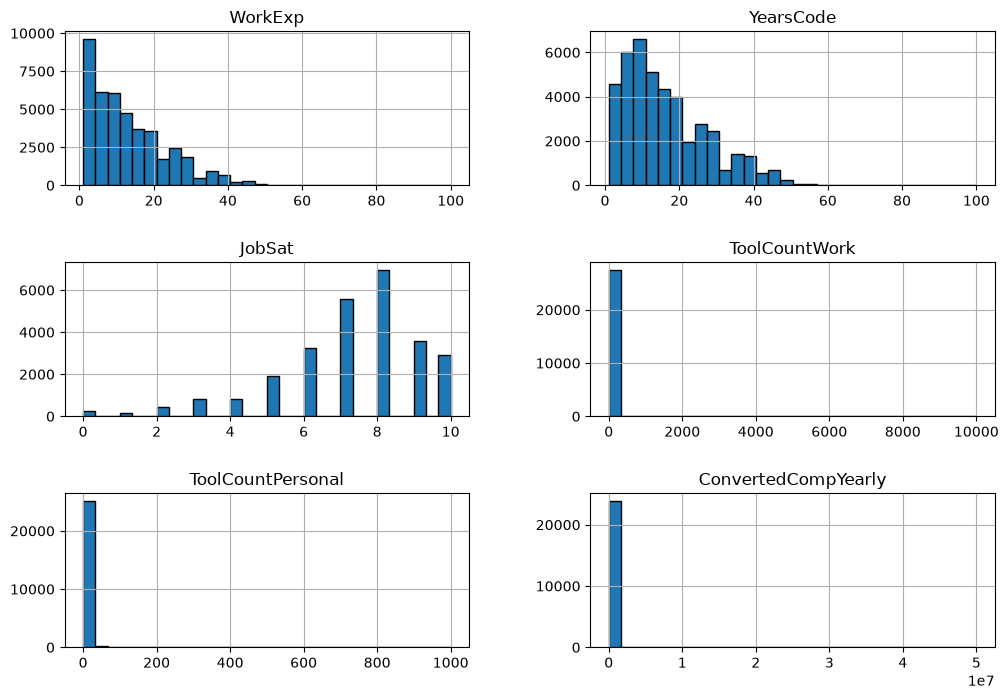

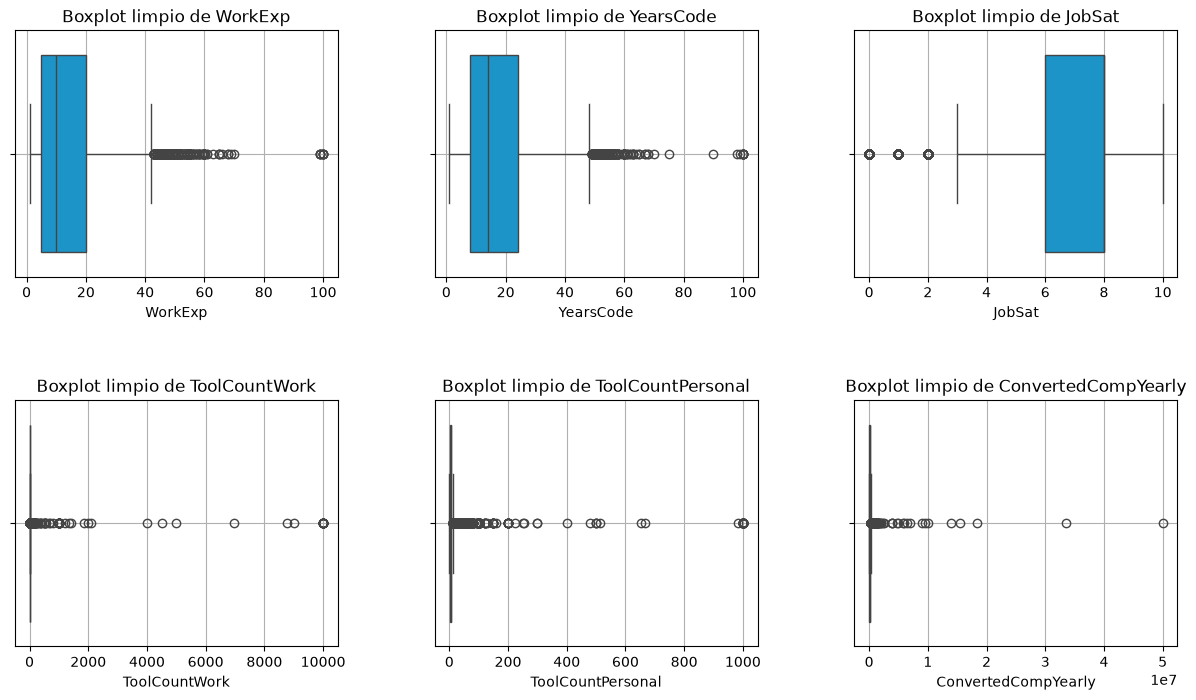

In [23]:
# Graficamos los histogramas de las variables cuantitativas ya limpias
preprocessed_dataset[columnas_cuantitativas].hist(figsize=(12, 8), bins=30, edgecolor="black")
plt.subplots_adjust(hspace=0.5, wspace=0.3)
plt.show()

# Graficamos los boxplots de las variables cuantitativas ya limpias
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(columnas_cuantitativas):
    sns.boxplot(x=preprocessed_dataset[col], ax=axes[i], color="#009FE4")
    axes[i].set_title(f"Boxplot limpio de {col}")
    axes[i].set_xlabel(col)
    axes[i].grid(True)

plt.subplots_adjust(hspace=0.5, wspace=0.3)
plt.show()

### 2.7. Preprocesamiento de la escala ordinal de confianza en la IA (`AIAcc`)
Mientras que en atributos por intervalos como `Age` resulta más claro conservar las etiquetas del intervalo original (ya que luego de limpiar `"Prefer not to say"` sus rangos quedan ordenados naturalmente de `"18-24 years old"` a `"65 years or older"`), en la variable **`AIAcc`** (confianza en la precisión de la IA) el orden alfabético mezcla los extremos (`"Highly distrust"` queda junto a `"Highly trust"`).

Siguiendo lo visto en la práctica, conservamos la columna original y creamos `aiacc_ordinal` mediante el método `map()`, asignando valores de **1 a 5** desde la menor hasta la mayor confianza para poder analizar su relación con la experiencia profesional.

Referencia: Práctica 4, sección 6, páginas 15–17. La numeración de `AIAcc` representa un orden y no prueba que las distancias entre categorías sean iguales.

In [24]:
# Verificamos que los intervalos de Age ya quedan ordenados de menor a mayor usando sort_index()
print("Intervalos de Age conservados y ordenados:")
print(preprocessed_dataset["Age"].value_counts().sort_index())

# Mapeamos AIAcc a una escala ordinal del 1 al 5 (conservando también la columna original AIAcc)
aiacc_map = {
    "Highly distrust": 1,
    "Somewhat distrust": 2,
    "Neither trust nor distrust": 3,
    "Somewhat trust": 4,
    "Highly trust": 5
}
preprocessed_dataset["aiacc_ordinal"] = preprocessed_dataset["AIAcc"].map(aiacc_map)

print("\nConteo de aiacc_ordinal (1 = Highly distrust ... 5 = Highly trust):")
print(preprocessed_dataset["aiacc_ordinal"].value_counts().sort_index())

Intervalos de Age conservados y ordenados:
Age
18-24 years old       8950
25-34 years old      16228
35-44 years old      13076
45-54 years old       6198
55-64 years old       2605
65 years or older      932
Name: count, dtype: int64

Conteo de aiacc_ordinal (1 = Highly distrust ... 5 = Highly trust):
aiacc_ordinal
1.0    6533
2.0    8685
3.0    7162
4.0    9869
5.0    1048
Name: count, dtype: int64


### 2.8. Creación de variables derivadas
Seguimos la sección 5 de la Práctica 4 (páginas 14–15), utilizando `apply()` y una función `lambda` para crear `is_daily_ai_user`, sin convertir los faltantes de `AISelect` en respuestas negativas.

También creamos `considers_new_role` mediante un diccionario y `map()` (Práctica 4, sección 6). Agrupamos las respuestas en tres categorías nominales: no consideró cambiar, lo consideró y ya realizó una transición. Las transiciones no se mezclan con la intención de cambiar; conservamos `NewRole` para no perder el detalle original.

In [25]:
# Creamos una variable booleana para identificar a quienes usan IA diariamente (entre quienes respondieron AISelect)
preprocessed_dataset["is_daily_ai_user"] = preprocessed_dataset["AISelect"].apply(
    lambda x: True if x == "Yes, I use AI tools daily" else (False if pd.notna(x) else np.nan)
)

print("Conteo de is_daily_ai_user:")
print(preprocessed_dataset["is_daily_ai_user"].value_counts(dropna=False))

# Agrupamos las respuestas de NewRole conservando la columna original
newrole_map = {
    "I have neither consider or transitioned into a new career or industry": "No consideró",
    "I have somewhat considered changing my career and/or the industry I work in": "Consideró",
    "I have strongly considered changing my career and/or the industry I work in": "Consideró",
    "I have transitioned into a new career and/or industry voluntarily": "Transicionó",
    "I have transitioned into a new career and/or industry involuntarily": "Transicionó"
}
preprocessed_dataset["considers_new_role"] = preprocessed_dataset["NewRole"].map(newrole_map)
print("Conteo de considers_new_role:")
print(preprocessed_dataset["considers_new_role"].value_counts(dropna=False))
print("Dimensiones después de crear las variables:", preprocessed_dataset.shape)
preprocessed_dataset.head()

Conteo de is_daily_ai_user:
is_daily_ai_user
False    17837
True     15883
NaN      14619
Name: count, dtype: int64
Conteo de considers_new_role:
considers_new_role
No consideró    16205
Consideró       15486
NaN             12812
Transicionó      3836
Name: count, dtype: int64
Dimensiones después de crear las variables: (48339, 42)


,ResponseId,MainBranch,Age,EdLevel,Employment,RemoteWork,OrgSize,ICorPM,DevType,Country,WorkExp,YearsCode,ToolCountWork,ToolCountPersonal,LanguageHaveWorkedWith,OpSysProfessional use,Currency,CompTotal,ConvertedCompYearly,AISelect,AIAcc,AISent,AIThreat,JobSat,NewRole,JobSatPoints_1,JobSatPoints_2,JobSatPoints_3,JobSatPoints_4,JobSatPoints_5,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,JobSatPoints_13,JobSatPoints_14,JobSatPoints_16,aiacc_ordinal,is_daily_ai_user,considers_new_role
0,1,I am a developer by profession,25-34 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Employed,Remote,20 to 99 employees,People manager,"Developer, mobile",Ukraine,8.0,14.0,7.0,3.0,Bash/Shell (all shells);Dart;SQL,Windows;MacOS;Android;iOS;iPadOS,EUR European Euro,52800.0,61256.0,"Yes, I use AI tools monthly or infrequently",Neither trust nor distrust,Indifferent,I'm not sure,10.0,I have neither consider or transitioned into a...,3.0,1.0,4.0,9.0,5.0,10.0,12.0,11.0,2.0,6.0,7.0,13.0,14.0,8.0,3.0,False,No consideró
1,2,I am a developer by profession,25-34 years old,"Associate degree (A.A., A.S., etc.)",Employed,"Hybrid (some in-person, leans heavy to flexibi...",500 to 999 employees,Individual contributor,"Developer, back-end",Netherlands,2.0,10.0,6.0,5.0,Java,MacOS,EUR European Euro,90000.0,104413.0,"Yes, I use AI tools weekly",Neither trust nor distrust,Indifferent,I'm not sure,9.0,I have transitioned into a new career and/or i...,10.0,8.0,3.0,9.0,12.0,1.0,6.0,2.0,11.0,4.0,7.0,13.0,14.0,5.0,3.0,False,Transicionó
2,3,I am a developer by profession,35-44 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)","Independent contractor, freelancer, or self-em...",NaN,NaN,NaN,"Developer, front-end",Ukraine,10.0,12.0,3.0,3.0,Dart;HTML/CSS;JavaScript;TypeScript,MacOS,UAH Ukrainian hryvnia,2214000.0,53061.0,"Yes, I use AI tools daily",Somewhat trust,Favorable,No,8.0,I have transitioned into a new career and/or i...,9.0,6.0,7.0,11.0,8.0,12.0,1.0,5.0,2.0,4.0,3.0,13.0,14.0,10.0,4.0,True,Transicionó
3,4,I am a developer by profession,35-44 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Employed,Remote,"10,000 or more employees",Individual contributor,"Developer, back-end",Ukraine,4.0,5.0,NaN,NaN,Java;Kotlin;SQL,Windows;Ubuntu,EUR European Euro,31200.0,36197.0,"Yes, I use AI tools weekly",Somewhat trust,Favorable,No,6.0,I have neither consider or transitioned into a...,1.0,2.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,11.0,12.0,13.0,14.0,3.0,4.0,False,No consideró
4,5,I am a developer by profession,35-44 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)","Independent contractor, freelancer, or self-em...",NaN,NaN,NaN,Engineering manager,Ukraine,21.0,22.0,4.0,3.0,C;C#;C++;Delphi;HTML/CSS;Java;JavaScript;Lua;P...,Windows;Ubuntu;Debian,USD United States dollar,60000.0,60000.0,"Yes, I use AI tools weekly",Neither trust nor distrust,Favorable,No,7.0,I have neither consider or transitioned into a...,9.0,4.0,11.0,13.0,14.0,8.0,6.0,5.0,7.0,2.0,1.0,12.0,10.0,3.0,3.0,False,No consideró


### 2.9. Guardado del conjunto limpio
Guardamos el DataFrame después de crear todas las variables derivadas, utilizando `to_pickle()` como en la Práctica 2 (página 9). Así, el archivo incluye `aiacc_ordinal`, `is_daily_ai_user` y `considers_new_role`.

In [26]:
# Revisamos las dimensiones finales del dataset preprocesado
print(f"Dimensiones finales de preprocessed_dataset: {preprocessed_dataset.shape}")

# Guardamos el dataset limpio en formato pickle
preprocessed_dataset.to_pickle("dataset_limpio.pkl")
print("Archivo 'dataset_limpio.pkl' guardado correctamente.")

Dimensiones finales de preprocessed_dataset: (48339, 42)
Archivo 'dataset_limpio.pkl' guardado correctamente.



### 3. Planteo de hipótesis propias del grupo

A partir de la exploración realizada sobre los atributos del conjunto de datos y utilizando conocimiento del dominio sobre la industria del software, planteamos las siguientes tres hipótesis de interés (una univariada, una bivariada y una multivariada) para su posterior validación:

### 3.1. Hipótesis Univariada (Confianza en la precisión de la IA - `AIAcc`)
* **Planteo:** *"A pesar de la masificación de los asistentes de programación basados en Inteligencia Artificial, menos del 10% de los desarrolladores que utilizan o evalúan estas herramientas tiene confianza total (`Highly trust`) en la precisión de sus respuestas, mientras que más del 40% manifiesta algún grado de desconfianza (`Somewhat distrust` o `Highly distrust`)."*
* **Justificación desde el dominio:** Si bien herramientas como ChatGPT, GitHub Copilot o Claude se adoptaron rápidamente para acelerar la escritura de código repetitivo (*boilerplate*), en la práctica cotidiana del desarrollo de software los modelos de lenguaje suelen presentar "alucinaciones" (inventar librerías o métodos inexistentes), cometer errores sutiles de lógica o proponer soluciones inseguras ante problemas complejos. Por este motivo, esperamos observar que la gran mayoría de los programadores mantiene un criterio escéptico y necesita revisar o corregir manualmente el código generado, siendo una pequeña minoría quienes confían ciegamente en la IA.

### 3.2. Hipótesis Bivariada (Comparación salarial entre Estados Unidos e India - `Country` vs. `ConvertedCompYearly`)
* **Planteo:** *"Al comparar dos de los mercados con mayor volumen de desarrolladores del mundo, Estados Unidos (`United States of America`) presenta un salario anual promedio y mediano en dólares (`ConvertedCompYearly`) significativamente más alto que India (`India`), reflejando el menor costo de la mano de obra en este último país."*
* **Justificación desde el dominio:** En la industria global de tecnología, Estados Unidos concentra las casas matrices de las principales empresas de software (*Big Tech*) y startups con mayor financiamiento, además de poseer un alto costo de vida local, lo que impulsa los salarios más elevados del mercado. Por el contrario, India se consolidó históricamente como el principal destino mundial de *offshoring* y subcontratación de servicios de ingeniería de software, compitiendo internacionalmente a través de una gran oferta de profesionales calificados con costos laborales en dólares sustancialmente más bajos.

### 3.3. Hipótesis Multivariada (Experiencia `WorkExp`, Edad `Age`, Salario `ConvertedCompYearly` y Uso de IA `AISelect`)
* **Planteo:** *"Los profesionales con mayor cantidad de años de experiencia laboral (`WorkExp`) se concentran en los rangos de mayor edad (`Age`), perciben los salarios anuales más elevados (`ConvertedCompYearly`) y, simultáneamente, registran una menor tasa de uso diario de herramientas de IA (`AISelect`) en comparación con los desarrolladores más jóvenes y de menor antigüedad."*
* **Justificación desde el dominio:** En la ingeniería de software, la antigüedad laboral está naturalmente correlacionada con la edad biológica y permite acceder a roles de mayor jerarquía (*Senior*, *Staff*, *Architect* o *Manager*), los cuales son los mejor remunerados del mercado. Al mismo tiempo, planteamos que estos perfiles experimentados —quienes se formaron y consolidaron sus hábitos de programación mucho antes de la aparición de los LLMs leyendo documentación oficial y foros como Stack Overflow— podrían mostrar mayor resistencia o menor dependencia hacia el uso diario de la IA que las nuevas generaciones de programadores, quienes ya aprendieron a programar integrando asistentes de IA desde el inicio de su carrera.

---

# 4. Validación de las hipótesis y discusión de resultados

En esta sección aplicamos técnicas de análisis descriptivo y visualización de datos para contrastar empíricamente las seis hipótesis del trabajo (tres propuestas por el grupo y tres obligatorias de la cátedra).

### 4.1. Validación de Hipótesis Univariada (Confianza en la precisión de la IA)
**Hipótesis planteada:** *"Menos del 10% de los desarrolladores tiene confianza total (`Highly trust`) en la precisión de las herramientas de IA, mientras que más del 40% manifiesta algún grado de desconfianza (`Somewhat distrust` o `Highly distrust`)."*

Para validarla, aislamos la variable cualitativa ordinal `AIAcc` (excluyendo los nulos) y analizamos sus frecuencias relativas. Luego, representamos la distribución completa mediante un gráfico de barras ordenado y un gráfico de proporciones para verificar los umbrales propuestos.

=== Distribución de Confianza en la Precisión de la IA (AIAcc) ===
                            Cantidad  Porcentaje (%)
AIAcc                                               
Highly distrust                 6533           19.62
Somewhat distrust               8685           26.08
Neither trust nor distrust      7162           21.51
Somewhat trust                  9869           29.64
Highly trust                    1048            3.15

-> Porcentaje con confianza total ('Highly trust'): 3.15%
-> Porcentaje con algún grado de desconfianza: 45.70%

CONCLUSIÓN: La hipótesis se CONFIRMA empíricamente.


C:\Users\Administrator\AppData\Local\Temp\ipykernel_24360\749059149.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


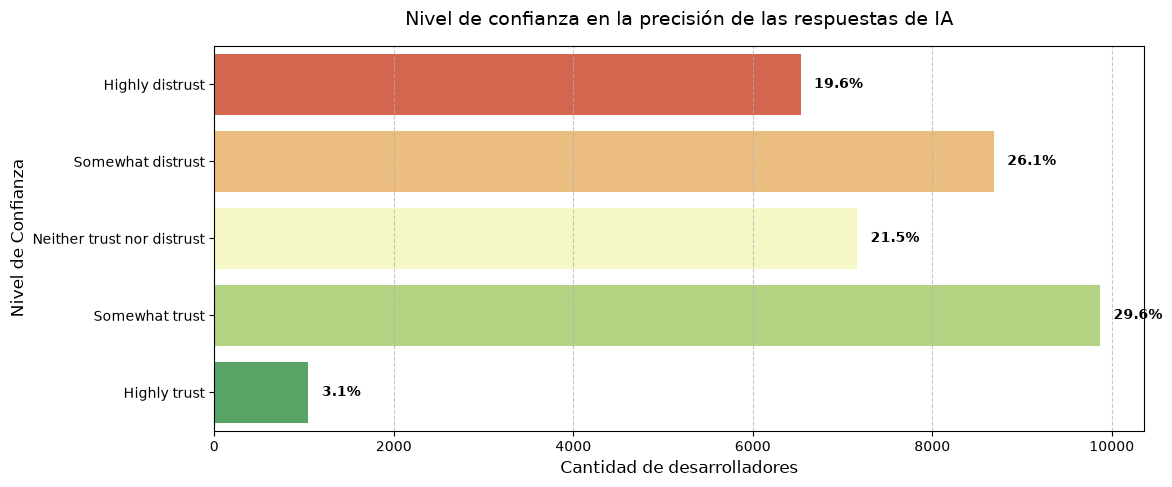

In [28]:
# Aislamos la columna AIAcc quitando los valores nulos para el análisis de proporciones
aiacc_valida = preprocessed_dataset["AIAcc"].dropna()

# Calculamos frecuencias absolutas y porcentajes
conteo_aiacc = aiacc_valida.value_counts()
porcentaje_aiacc = aiacc_valida.value_counts(normalize=True) * 100

# Armamos un DataFrame resumen para mostrar la tabla de forma prolija
tabla_aiacc = pd.DataFrame({
    "Cantidad": conteo_aiacc,
    "Porcentaje (%)": porcentaje_aiacc.round(2)
})

# Definimos el orden lógico de las categorías para los gráficos (de menor a mayor confianza)
orden_likert = [
    "Highly distrust", "Somewhat distrust", 
    "Neither trust nor distrust", 
    "Somewhat trust", "Highly trust"
]

print("=== Distribución de Confianza en la Precisión de la IA (AIAcc) ===")
print(tabla_aiacc.loc[orden_likert])

# Extraemos los porcentajes clave para validar la hipótesis
porcentaje_highly_trust = porcentaje_aiacc.get("Highly trust", 0)
porcentaje_desconfianza = porcentaje_aiacc.get("Highly distrust", 0) + porcentaje_aiacc.get("Somewhat distrust", 0)

print(f"\n-> Porcentaje con confianza total ('Highly trust'): {porcentaje_highly_trust:.2f}%")
print(f"-> Porcentaje con algún grado de desconfianza: {porcentaje_desconfianza:.2f}%")

# Verificamos la hipótesis lógicamente
if porcentaje_highly_trust < 10 and porcentaje_desconfianza > 40:
    print("\nCONCLUSIÓN: La hipótesis se CONFIRMA empíricamente.")
else:
    print("\nCONCLUSIÓN: La hipótesis es REFUTADA por los datos.")

# --- Visualización 1: Gráfico de barras ordenado ---
plt.figure(figsize=(12, 5))
ax = sns.countplot(
    data=preprocessed_dataset, 
    y="AIAcc", 
    order=orden_likert, 
    palette="RdYlGn" # Paleta de colores semántica: Rojo (desconfianza) a Verde (confianza)
)

plt.title("Nivel de confianza en la precisión de las respuestas de IA", fontsize=14, pad=15)
plt.xlabel("Cantidad de desarrolladores", fontsize=12)
plt.ylabel("Nivel de Confianza", fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)

# Agregamos las etiquetas de porcentaje en cada barra
for p in ax.patches:
    width = p.get_width()
    if width > 0:
        porcentaje = (width / len(aiacc_valida)) * 100
        ax.text(width + 150, p.get_y() + p.get_height()/2, f'{porcentaje:.1f}%', va='center', fontweight='bold')

plt.show()



### 4.2. Validación de Hipótesis Bivariada (EE. UU. vs. India)
**Hipótesis planteada:** *"Estados Unidos presenta un salario anual promedio y mediano en dólares (`ConvertedCompYearly`) significativamente más alto (más del doble) que India, reflejando el menor costo de la mano de obra en este último país."*

Siguiendo lo visto en la Práctica 2 y 5, validamos esta hipótesis cruzando una variable categórica (`Country`) con una numérica (`ConvertedCompYearly`). Filtramos el conjunto de datos para conservar únicamente a los encuestados de ambos países y utilizamos `groupby()` para calcular las medidas de tendencia central. Finalmente, empleamos un boxplot para comparar visualmente las distribuciones y el intervalo de confianza de sus medianas, evitando gráficos de barras que ocultarían la dispersión real de los salarios.

=== Estadísticas Salariales Anuales (USD) por País ===
                          count       mean    median
Country                                             
India                      1096   44291.79   17029.0
United States of America   5243  179804.50  150000.0

-> Mediana salarial en EE. UU.: $150,000.00
-> Mediana salarial en India: $17,029.00
-> La mediana en EE. UU. es 8.81 veces mayor que en India.

CONCLUSIÓN: La hipótesis se CONFIRMA empíricamente.


C:\Users\Administrator\AppData\Local\Temp\ipykernel_24360\4174118159.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


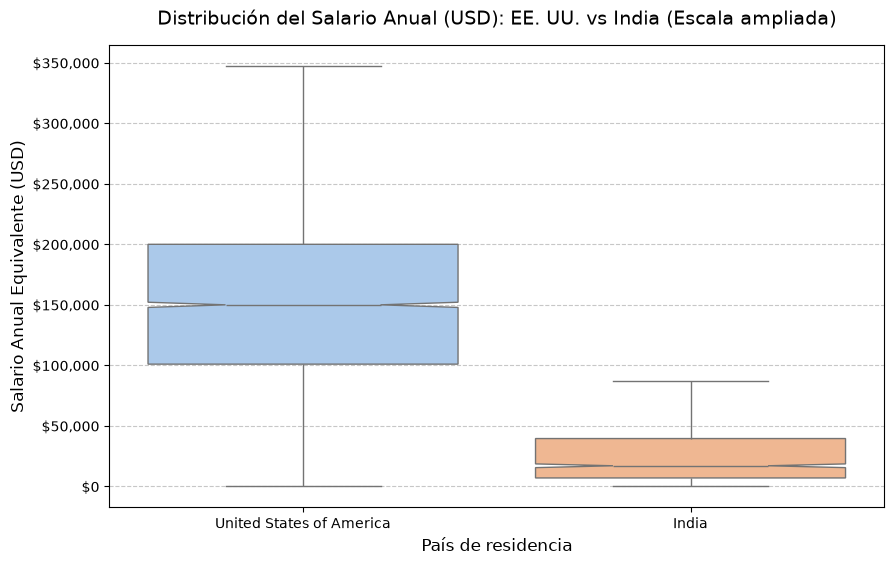

In [ ]:
# Filtramos el dataset original limpio para quedarnos solo con Estados Unidos e India
paises_interes = ["United States of America", "India"]
df_paises = preprocessed_dataset[preprocessed_dataset["Country"].isin(paises_interes)].copy()

# Descartamos las filas donde el sueldo sea nulo para no afectar las estadísticas
df_paises = df_paises.dropna(subset=["ConvertedCompYearly"])

# Utilizamos groupby (Práctica 2) para calcular cantidad, media y mediana por país
stats_salario = df_paises.groupby("Country")["ConvertedCompYearly"].agg(["count", "mean", "median"])

print("=== Estadísticas Salariales Anuales (USD) por País ===")
print(stats_salario.round(2))

# Extraemos las medianas para validar la proporción planteada en la hipótesis
mediana_usa = stats_salario.loc["United States of America", "median"]
mediana_india = stats_salario.loc["India", "median"]
ratio_mediana = mediana_usa / mediana_india

print(f"\n-> Mediana salarial en EE. UU.: ${mediana_usa:,.2f}")
print(f"-> Mediana salarial en India: ${mediana_india:,.2f}")
print(f"-> La mediana en EE. UU. es {ratio_mediana:.2f} veces mayor que en India.")

if ratio_mediana > 2:
    print("\nCONCLUSIÓN: La hipótesis se CONFIRMA empíricamente.")
else:
    print("\nCONCLUSIÓN: La hipótesis es REFUTADA por los datos.")

# --- Visualización (Práctica 5) ---
plt.figure(figsize=(10, 6))

# Usamos boxplot con notch=True y showfliers=False para ocultar los valores extremos del dibujo
sns.boxplot(
    data=df_paises, 
    x="Country", 
    y="ConvertedCompYearly", 
    notch=True, 
    palette="pastel",
    showfliers=False  
)

plt.title("Distribución del Salario Anual (USD): EE. UU. vs India (Escala ampliada)", fontsize=14, pad=15)
plt.xlabel("País de residencia", fontsize=12)
plt.ylabel("Salario Anual Equivalente (USD)", fontsize=12)

# Formateamos el eje Y para evitar notación científica y mostrar separador de miles
plt.gca().yaxis.set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter('${x:,.0f}'))
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

### 4.3. Validación de Hipótesis Multivariada (Experiencia, Edad, Salario y Uso de IA)
**Hipótesis planteada:** *"Los profesionales con mayor cantidad de años de experiencia laboral (`WorkExp`) se concentran en los rangos de mayor edad (`Age`), perciben los salarios anuales más elevados (`ConvertedCompYearly`) y, simultáneamente, registran una menor tasa de uso diario de herramientas de IA (`AISelect`) en comparación con los desarrolladores más jóvenes."*

Para validar esta convergencia de cuatro variables, utilizamos un enfoque mixto. Primero, construimos un gráfico de dispersión (`scatterplot`) que relaciona los años de experiencia con el salario anual, utilizando el color (`hue`) para segmentar por rangos de edad. Aplicamos una escala logarítmica al eje Y para neutralizar el impacto visual de los valores atípicos salariales. Finalmente, agrupamos los datos por edad para extraer las medianas salariales y calcular matemáticamente la tasa de adopción diaria de IA, demostrando si existe la correlación inversa planteada.

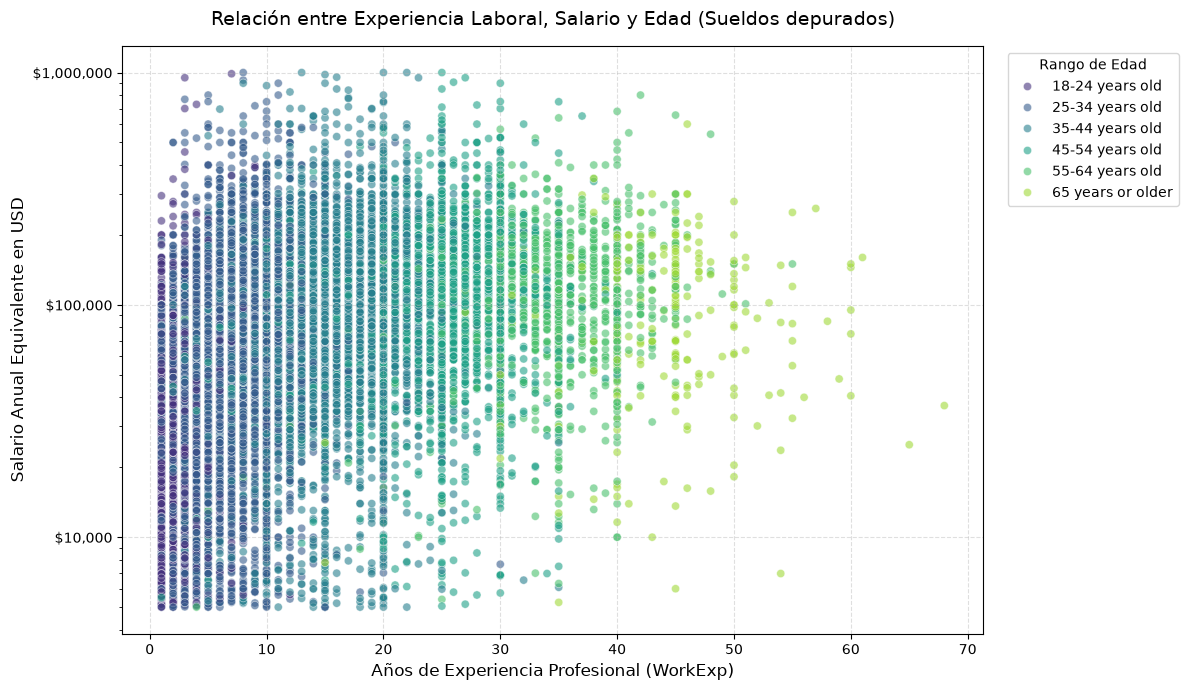

=== Perfil Multivariado por Rango de Edad (Datos Depurados) ===
                   Mediana_Exp_Años  Mediana_Sueldo_USD  Porcentaje_IA_Diaria
Age                                                                          
18-24 years old                 2.0             34511.0                  52.0
25-34 years old                 7.0             68071.0                  50.7
35-44 years old                15.0             94118.5                  49.9
45-54 years old                25.0            104413.0                  46.3
55-64 years old                34.0            110000.0                  33.7
65 years or older              43.0            100000.0                  27.7

--- Verificación de las condiciones ---
¿Los mayores tienen más experiencia? Sí
¿Los mayores perciben mayor salario? Sí
¿Los mayores tienen MENOR uso diario de IA? Sí

CONCLUSIÓN: La hipótesis se CONFIRMA empíricamente.


In [ ]:
# 1. Filtramos los nulos de las 4 variables involucradas
columnas_multi = ["WorkExp", "Age", "ConvertedCompYearly", "AISelect"]
df_multi = preprocessed_dataset.dropna(subset=columnas_multi).copy()

# Definimos el orden cronológico
orden_edades = [
    "18-24 years old", "25-34 years old", 
    "35-44 years old", "45-54 years old", 
    "55-64 years old", "65 years or older"
]
df_multi = df_multi[df_multi["Age"].isin(orden_edades)]

# --- EL FILTRO SALVADOR PARA EL GRÁFICO ---
# Recortamos los sueldos irreales (errores de conversión o trolls) solo para este análisis.
# Conservamos un rango realista para la industria IT global: entre 5.000 y 1.000.000 USD.
df_multi_limpio = df_multi[
    (df_multi["ConvertedCompYearly"] >= 5000) & 
    (df_multi["ConvertedCompYearly"] <= 1000000)
]

# --- Visualización ---
plt.figure(figsize=(12, 7))

# Usamos el dataframe filtrado (df_multi_limpio)
sns.scatterplot(
    data=df_multi_limpio,
    x="WorkExp",
    y="ConvertedCompYearly",
    hue="Age",
    hue_order=orden_edades,
    palette="viridis",
    alpha=0.6,
    s=35
)

plt.title("Relación entre Experiencia Laboral, Salario y Edad (Sueldos depurados)", fontsize=14, pad=15)
plt.xlabel("Años de Experiencia Profesional (WorkExp)", fontsize=12)
plt.ylabel("Salario Anual Equivalente en USD", fontsize=12)

# Mantenemos la escala logarítmica porque sigue siendo útil para ver la progresión
plt.yscale('log')
plt.gca().yaxis.set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter('${x:,.0f}'))

plt.grid(axis='both', linestyle='--', alpha=0.4)
plt.legend(title="Rango de Edad", bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

# --- Análisis Estadístico Multivariado ---
df_multi_limpio["Usa_IA_Diario"] = df_multi_limpio["AISelect"] == "Yes, I use AI tools daily"

stats_multi = df_multi_limpio.groupby("Age").agg(
    Mediana_Exp_Años=("WorkExp", "median"),
    Mediana_Sueldo_USD=("ConvertedCompYearly", "median"),
    Porcentaje_IA_Diaria=("Usa_IA_Diario", lambda x: x.mean() * 100)
).reindex(orden_edades)

print("=== Perfil Multivariado por Rango de Edad (Datos Depurados) ===")
print(stats_multi.round(1))

# --- Verificación automática de la hipótesis ---
grupo_joven = stats_multi.loc["18-24 years old"]
grupo_senior = stats_multi.loc["45-54 years old"]

mayor_experiencia = grupo_senior["Mediana_Exp_Años"] > grupo_joven["Mediana_Exp_Años"]
mayor_sueldo = grupo_senior["Mediana_Sueldo_USD"] > grupo_joven["Mediana_Sueldo_USD"]
menor_uso_ia = grupo_senior["Porcentaje_IA_Diaria"] < grupo_joven["Porcentaje_IA_Diaria"]

print("\n--- Verificación de las condiciones ---")
print(f"¿Los mayores tienen más experiencia? {'Sí' if mayor_experiencia else 'No'}")
print(f"¿Los mayores perciben mayor salario? {'Sí' if mayor_sueldo else 'No'}")
print(f"¿Los mayores tienen MENOR uso diario de IA? {'Sí' if menor_uso_ia else 'No'}")

if mayor_experiencia and mayor_sueldo and menor_uso_ia:
    print("\nCONCLUSIÓN: La hipótesis se CONFIRMA")
else:
    print("\nCONCLUSIÓN: La hipótesis es REFUTADA por los datos.")

### 4.4. Validación de Hipótesis Obligatoria A (Salario en Argentina vs. SMVM)
**Hipótesis de la cátedra:** *"Los desarrolladores que respondieron la encuesta de Argentina tienen un salario 3 veces mayor al Salario Mínimo, Vital y Móvil (SMVM)."*

Para contrastar esta hipótesis, tomamos como referencia el SMVM de octubre de 2026 ($391.200 ARS). Para poder compararlo con la variable `ConvertedCompYearly` (que expresa el salario anual en dólares), anualizamos el SMVM (multiplicándolo por 12 meses) y lo convertimos a dólares utilizando un tipo de cambio financiero de referencia. Luego, filtramos la base para retener únicamente a los encuestados de Argentina, calculamos su mediana salarial, y la contrastamos contra el umbral de los 3 SMVM anualizados utilizando un diagrama de caja con una línea de corte.

=== Análisis Salarial: Argentina vs. 3 SMVM ===
-> SMVM Mensual (ARS): $391.200
-> SMVM Anual estimado (USD): $2,990
-> UMBRAL (3 veces el SMVM Anual en USD): $8,970
-> Mediana Salarial Anual de un Dev en Argentina (USD): $42,653

CONCLUSIÓN: La hipótesis se CONFIRMA empíricamente.


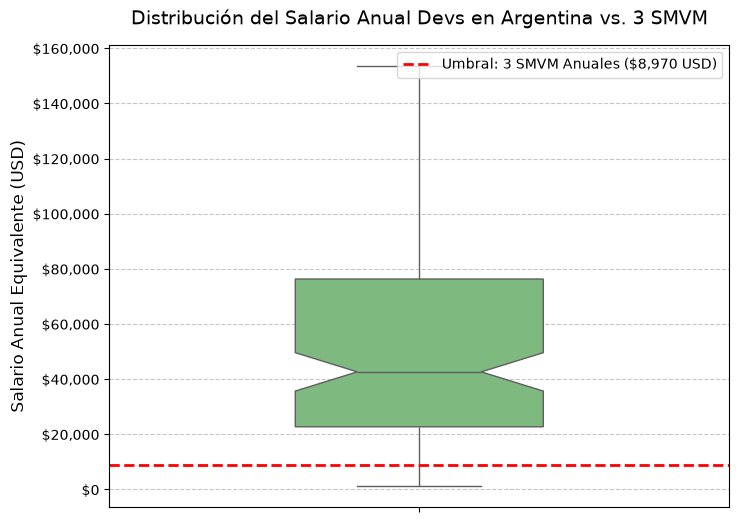

In [38]:
# Definimos los valores económicos de referencia
smvm_mensual_ars = 391200
smvm_anual_ars = smvm_mensual_ars * 12

# Definimos un tipo de cambio estimado (ARS a USD) para estandarizar la métrica.
# NOTA: Ajustar este valor a la cotización (MEP/Blue) que el grupo considere representativa.
tipo_cambio_usd = 1570

smvm_anual_usd = smvm_anual_ars / tipo_cambio_usd
umbral_3_smvm_usd = smvm_anual_usd * 3

# Filtramos la base: Solo Argentina y descartamos nulos/valores extremos para no distorsionar
df_arg = preprocessed_dataset[
    (preprocessed_dataset["Country"] == "Argentina") & 
    (preprocessed_dataset["ConvertedCompYearly"].notna()) &
    (preprocessed_dataset["ConvertedCompYearly"] >= 1000) & 
    (preprocessed_dataset["ConvertedCompYearly"] <= 500000)
].copy()

# Calculamos la mediana de los sueldos en Argentina
mediana_arg = df_arg["ConvertedCompYearly"].median()

print("=== Análisis Salarial: Argentina vs. 3 SMVM ===")
print(f"-> SMVM Mensual (ARS): ${smvm_mensual_ars:,.0f}".replace(",", "."))
print(f"-> SMVM Anual estimado (USD): ${smvm_anual_usd:,.0f}")
print(f"-> UMBRAL (3 veces el SMVM Anual en USD): ${umbral_3_smvm_usd:,.0f}")
print(f"-> Mediana Salarial Anual de un Dev en Argentina (USD): ${mediana_arg:,.0f}\n")

# Verificación de la hipótesis
if mediana_arg > umbral_3_smvm_usd:
    print("CONCLUSIÓN: La hipótesis se CONFIRMA empíricamente.")
else:
    print("CONCLUSIÓN: La hipótesis es REFUTADA por los datos.")

# --- Visualización ---
plt.figure(figsize=(8, 6))

# Boxplot de los salarios en Argentina (sin outliers visuales para mejor legibilidad)
sns.boxplot(
    y=df_arg["ConvertedCompYearly"], 
    color="#74c476", 
    notch=True, 
    showfliers=False,
    width=0.4
)

# Agregamos la línea de corte del umbral (3 SMVM)
plt.axhline(
    y=umbral_3_smvm_usd, 
    color='red', 
    linestyle='--', 
    linewidth=2, 
    label=f'Umbral: 3 SMVM Anuales (${umbral_3_smvm_usd:,.0f} USD)'
)

plt.title("Distribución del Salario Anual Devs en Argentina vs. 3 SMVM", fontsize=14, pad=15)
plt.ylabel("Salario Anual Equivalente (USD)", fontsize=12)
plt.gca().yaxis.set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter('${x:,.0f}'))
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(loc='upper right')

plt.show()

### 4.5. Validación de Hipótesis Obligatoria B (Experiencia vs. Confianza en IA)
**Hipótesis de la cátedra:** *"Los años de experiencia profesional influyen en la confianza en la precisión de las herramientas de IA."*

Para evaluar esta hipótesis bivariada, cruzamos una variable numérica (`WorkExp`) con una variable categórica ordinal (`AIAcc`). Siguiendo los lineamientos de las prácticas, calculamos las medidas de tendencia central (mediana y promedio de años de experiencia) agrupadas por cada nivel de confianza. Luego, visualizamos la distribución mediante un diagrama de caja (`boxplot`) horizontal. Esto nos permite observar si la masa salarial más experimentada tiende a desconfiar más o menos de las herramientas de Inteligencia Artificial que los perfiles junior.

=== Años de Experiencia Profesional según Confianza en la IA ===
                            count  median   mean
AIAcc                                           
Highly distrust              5990    12.0  14.57
Somewhat distrust            8037    12.0  14.20
Neither trust nor distrust   6673    11.0  14.07
Somewhat trust               9140    11.0  13.58
Highly trust                  922    10.0  13.15

-> Mediana de exp. en 'Highly distrust': 12.0 años
-> Mediana de exp. en 'Highly trust': 10.0 años
-> Diferencia observada: 2.0 años

--- VERIFICACIÓN DE SIGNIFICANCIA ESTADÍSTICA ---
Para confirmar que esta diferencia no es producto del azar, evaluamos el intervalo de confianza visual (notches).
CONCLUSIÓN: Los datos muestran una variación de al menos 1 año. Si en el gráfico inferior las muescas de los extremos NO se superponen verticalmente, la hipótesis se CONFIRMA con significancia estadística.


C:\Users\Administrator\AppData\Local\Temp\ipykernel_24360\3355707742.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


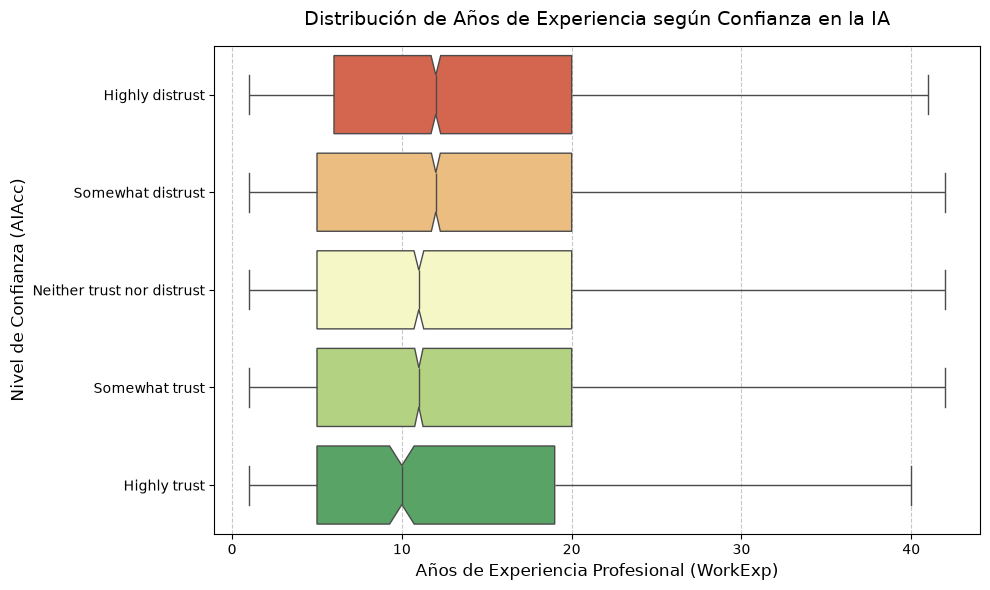

In [40]:
# Filtramos el dataset para quedarnos solo con las dos variables de interés (sin nulos)
df_exp_ia = preprocessed_dataset.dropna(subset=["WorkExp", "AIAcc"]).copy()

# Definimos el orden lógico de la escala Likert (de menor a mayor confianza)
orden_likert = [
    "Highly distrust", "Somewhat distrust", 
    "Neither trust nor distrust", 
    "Somewhat trust", "Highly trust"
]

# Agrupamos por nivel de confianza y calculamos la experiencia mediana y promedio
stats_ia = df_exp_ia.groupby("AIAcc")["WorkExp"].agg(["count", "median", "mean"])
stats_ia = stats_ia.reindex(orden_likert)

print("=== Años de Experiencia Profesional según Confianza en la IA ===")
print(stats_ia.round(2))

# Extraemos las medianas de los extremos
mediana_desconfianza = stats_ia.loc["Highly distrust", "median"]
mediana_confianza = stats_ia.loc["Highly trust", "median"]
diferencia_absoluta = abs(mediana_desconfianza - mediana_confianza)

print(f"\n-> Mediana de exp. en 'Highly distrust': {mediana_desconfianza} años")
print(f"-> Mediana de exp. en 'Highly trust': {mediana_confianza} años")
print(f"-> Diferencia observada: {diferencia_absoluta} años")

# Agregamos la aclaración metodológica sobre la significancia
print("\n--- VERIFICACIÓN DE SIGNIFICANCIA ESTADÍSTICA ---")
print("Para confirmar que esta diferencia no es producto del azar, evaluamos el intervalo de confianza visual (notches).")

if diferencia_absoluta >= 1.0:
    print("CONCLUSIÓN: Los datos muestran una variación de al menos 1 año. Si en el gráfico inferior las muescas de los extremos NO se superponen verticalmente, la hipótesis se CONFIRMA con significancia estadística.")
else:
    print("CONCLUSIÓN: La diferencia empírica es mínima. Si en el gráfico las muescas se superponen, la hipótesis es REFUTADA.")

# --- Visualización ---
plt.figure(figsize=(10, 6))

# Boxplot horizontal para ver la distribución y validar la significancia con las muescas (notch=True)
sns.boxplot(
    data=df_exp_ia,
    x="WorkExp",
    y="AIAcc",
    order=orden_likert,
    palette="RdYlGn",
    notch=True,
    showfliers=False
)

plt.title("Distribución de Años de Experiencia según Confianza en la IA", fontsize=14, pad=15)
plt.xlabel("Años de Experiencia Profesional (WorkExp)", fontsize=12)
plt.ylabel("Nivel de Confianza (AIAcc)", fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()